# Mammography results analysis

Cohort summaries, exploratory features, development trajectories, and frozen model comparisons.


In [1]:
from __future__ import annotations

import hashlib
import json
import os
import sys
import warnings
from io import BytesIO
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.ticker import MaxNLocator
from PIL import Image as PILImage
from IPython.display import Image, display

EXPECTED_PYTHON = Path(os.environ.get("MAMMO_PYTHON", "/home/azyqan/venvs/ml-torch/bin/python")).resolve()
assert Path(sys.executable).resolve() == EXPECTED_PYTHON

import os

_start = Path.cwd().resolve()
PROJECT_ROOT = next(
    candidate for candidate in (_start, *_start.parents)
    if (candidate / "notebooks").is_dir()
    and (candidate / "artifacts").is_dir()
    and (candidate / "dataset").is_dir()
)
DATASET_ROOT = Path(os.environ.get("MAMMO_DATA_ROOT", PROJECT_ROOT / "dataset")).expanduser().resolve()
WORK_DATA_ROOT = Path(os.environ.get("MAMMO_WORK_DATA_ROOT", PROJECT_ROOT / "dataset")).expanduser().resolve()
DICOM_ROOT = DATASET_ROOT / "images_dicom"
if not DICOM_ROOT.is_dir() and (DATASET_ROOT / "images").is_dir():
    DICOM_ROOT = DATASET_ROOT / "images"
ANNOTATIONS = DATASET_ROOT / "annotations"
if not ANNOTATIONS.is_dir():
    ANNOTATIONS = DATASET_ROOT
RAW_DIR = WORK_DATA_ROOT / "Raw"
PROCESSED_DIR = WORK_DATA_ROOT / "Processed"
CONFIG_DIR = PROJECT_ROOT / "dataset" / "protocol"
MODEL_DIR = Path(os.environ.get("MAMMO_MODEL_ROOT", WORK_DATA_ROOT / "checkpoints")).expanduser().resolve()
COHORT_TABLES = PROJECT_ROOT / "dataset"
EDA_TABLES = PROJECT_ROOT / "artifacts" / "eda"
MODEL_TABLES = PROJECT_ROOT / "artifacts" / "models"
FIGURE_ROOT = PROJECT_ROOT / "figures"
FIGURE_INDEX = json.loads((FIGURE_ROOT / "index.json").read_text(encoding="utf-8"))
FIGURE_PATHS = {item["source"]: item["path"] for item in FIGURE_INDEX}

def resolve_figure(relative_path: str) -> Path:
    return PROJECT_ROOT / FIGURE_PATHS.get(relative_path, relative_path)

def protocol_table(name: str) -> Path:
    if name in ["bcrf_checkpoint_lineage.csv","bcrf_deployment_lineage.csv","bcrf_freeze_manifest.csv","frozen_evaluation_input_lineage.csv"]:
        return CONFIG_DIR / name
    return MODEL_TABLES / name

def resolve_dicom(relative_path: str) -> Path:
    name = Path(relative_path).name
    direct = DICOM_ROOT / name
    if direct.is_file():
        return direct
    candidates = list(DICOM_ROOT.rglob(name))
    if len(candidates) != 1:
        raise FileNotFoundError(f"Expected one DICOM for {name}; found {len(candidates)}")
    return candidates[0]

def legacy_relative_path(path: Path) -> str:
    if path.name in ["bcrf_checkpoint_lineage.csv", "bcrf_deployment_lineage.csv", "bcrf_freeze_manifest.csv", "frozen_evaluation_input_lineage.csv"]:
        return "Tables/Models/" + path.name
    if path.is_relative_to(MODEL_DIR):
        return "Models/" + str(path.relative_to(MODEL_DIR))
    if path.is_relative_to(WORK_DATA_ROOT / "Raw"):
        return "Data/Raw/" + str(path.relative_to(WORK_DATA_ROOT / "Raw"))
    if path.is_relative_to(PROCESSED_DIR):
        return "Data/Processed/" + str(path.relative_to(PROCESSED_DIR))
    if path.is_relative_to(CONFIG_DIR):
        return "Config/" + str(path.relative_to(CONFIG_DIR))
    if path.is_relative_to(MODEL_TABLES):
        return "Tables/Models/" + str(path.relative_to(MODEL_TABLES))
    return str(path.relative_to(PROJECT_ROOT))

RASTER_LINEAGE = pd.DataFrame(FIGURE_INDEX).rename(columns={"source": "png_path", "sha256": "png_sha256"}).set_index("png_path")

DPI = 350

times_font = Path("/mnt/c/Windows/Fonts/times.ttf")
if times_font.is_file():
    font_manager.fontManager.addfont(times_font)
FONT_PATH = font_manager.findfont(
    os.environ.get("MAMMO_FONT", "Times New Roman"),
    fallback_to_default=False,
)
mpl.rcParams.update(
    {
        "font.family": os.environ.get("MAMMO_FONT", "Times New Roman"),
        "font.size": 18,
        "axes.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.titlesize": 20,
        "axes.unicode_minus": True,
        "savefig.dpi": DPI,
        "savefig.facecolor": "white",
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)
assert font_manager.FontProperties(fname=FONT_PATH).get_name() == os.environ.get("MAMMO_FONT", "Times New Roman")


In [2]:
def show_table(
    frame: pd.DataFrame,
    *,
    caption: str,
    columns: list[str] | None = None,
    precision: int = 4,
    highlight_max: list[str] | None = None,
):
    view = frame.loc[:, columns].copy() if columns else frame.copy()
    style = (
        view.style
        .hide(axis="index")
        .format(precision=precision, na_rep="—")
        .set_caption(caption)
        .set_table_styles(
            [
                {
                    "selector": "caption",
                    "props": [
                        ("caption-side", "top"),
                        ("font-weight", "bold"),
                        ("font-size", "20px"),
                        ("text-align", "left"),
                    ],
                },
                {
                    "selector": "th",
                    "props": [
                        ("font-size", "18px"),
                        ("text-align", "center"),
                    ],
                },
                {
                    "selector": "td",
                    "props": [
                        ("font-size", "18px"),
                        ("text-align", "center"),
                    ],
                },
            ]
        )
    )
    valid_highlights = [
        column
        for column in (highlight_max or [])
        if column in view.columns
    ]
    if valid_highlights:
        style = style.highlight_max(
            subset=valid_highlights,
            axis=0,
            props="font-weight: bold; background-color: #E6EEF8;",
        )
    display(style)

def format_number(value: float, decimals: int = 3) -> str:
    magnitude = f"{abs(value):.{decimals}f}"
    return f"−{magnitude}" if value < 0 else magnitude

def format_signed(value: float, decimals: int = 3) -> str:
    if value < 0:
        return f"−{abs(value):.{decimals}f}"
    return f"+{value:.{decimals}f}"


In [3]:
def display_scientific_figure(figure: plt.Figure) -> None:
    buffer = BytesIO()
    figure.savefig(
        buffer,
        format="png",
        dpi=DPI,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.close(figure)
    display(Image(data=buffer.getvalue()))

def clean_axis(axis: plt.Axes, *, grid_axis: str | None = None) -> None:
    axis.spines[["top", "right"]].set_visible(False)
    axis.tick_params(labelsize=18)
    if grid_axis is not None:
        axis.grid(
            axis=grid_axis,
            color="#D9D9D9",
            linewidth=1.2,
            alpha=0.8,
        )
        axis.set_axisbelow(True)

def display_horizontal_bars(
    labels: list[str],
    values: np.ndarray,
    *,
    title: str,
    xlabel: str,
    color: str = "#3B6EA8",
    decimals: int = 0,
) -> None:
    values = np.asarray(values, dtype=float)
    maximum = max(float(values.max()), 1.0)
    positions = np.arange(len(labels))
    height = max(3.4, 1.45 + 0.72 * len(labels))
    figure, axis = plt.subplots(
        figsize=(4.8, height),
        constrained_layout=True,
    )
    bars = axis.barh(positions, values, color=color, height=0.66)
    axis.set_yticks(positions, labels)
    axis.invert_yaxis()
    axis.set_xlim(0, maximum * 1.24)
    axis.xaxis.set_major_locator(MaxNLocator(nbins=4, integer=decimals == 0))
    for bar, value in zip(bars, values):
        inside = value >= 0.72 * maximum
        axis.text(
            value - 0.025 * maximum if inside else value + 0.025 * maximum,
            bar.get_y() + bar.get_height() / 2,
            format_number(value, decimals=decimals),
            ha="right" if inside else "left",
            va="center",
            color="white" if inside else "#222222",
            fontsize=18,
        )
    axis.set_xlabel(xlabel)
    axis.set_title(title, pad=12)
    clean_axis(axis, grid_axis="x")
    display_scientific_figure(figure)


In [4]:
def display_interval_plot(
    frame: pd.DataFrame,
    *,
    label_column: str,
    mean_column: str,
    low_column: str,
    high_column: str,
    title: str,
    xlabel: str,
    reference: float | None = None,
    highlight_label: str | None = None,
    decimals: int = 3,
    signed_values: bool = False,
) -> None:
    view = frame.reset_index(drop=True).copy()
    positions = np.arange(len(view))[::-1]
    lower = float(view[low_column].min())
    upper = float(view[high_column].max())
    if reference is not None:
        lower = min(lower, reference)
        upper = max(upper, reference)
    span = max(upper - lower, 0.05)
    left = min(0.0, lower) - 0.08 * span
    right = upper + 0.36 * span
    height = max(3.4, 1.45 + 0.68 * len(view))
    figure, axis = plt.subplots(
        figsize=(4.8, height),
        constrained_layout=True,
    )
    for position, row in zip(positions, view.itertuples()):
        label = str(getattr(row, label_column))
        mean = float(getattr(row, mean_column))
        low = float(getattr(row, low_column))
        high = float(getattr(row, high_column))
        color = "#B2182B" if label == highlight_label else "#4D4D4D"
        axis.errorbar(
            mean,
            position,
            xerr=np.array([[mean - low], [high - mean]]),
            fmt="o",
            markersize=8,
            capsize=6,
            linewidth=2.0,
            color=color,
        )
        axis.text(
            high + 0.045 * span,
            position,
            format_signed(mean, decimals) if signed_values else format_number(mean, decimals),
            ha="left",
            va="center",
            fontsize=18,
        )
    if reference is not None:
        axis.axvline(reference, color="#222222", linewidth=1.6, linestyle="--")
    axis.set_xlim(left, right)
    axis.set_yticks(positions, view[label_column])
    axis.xaxis.set_major_locator(MaxNLocator(nbins=4))
    axis.set_xlabel(xlabel)
    axis.set_title(title, pad=12)
    clean_axis(axis, grid_axis="x")
    display_scientific_figure(figure)

def display_raster_panel(
    relative_path: str,
    *,
    crop_box: tuple[int, int, int, int],
    title: str,
    colorbar_label: str | None = None,
    colormap: str = "inferno",
) -> None:
    path = resolve_figure(relative_path)
    assert path.is_file(), path
    expected_sha256 = str(
        RASTER_LINEAGE.loc[relative_path, "png_sha256"]
    )
    actual_sha256 = hashlib.sha256(path.read_bytes()).hexdigest()
    assert actual_sha256 == expected_sha256
    with PILImage.open(path) as source_image:
        width, height = source_image.size
        left, top, right, bottom = crop_box
        assert 0 <= left < right <= width
        assert 0 <= top < bottom <= height
        panel = np.asarray(source_image.convert("RGB").crop(crop_box))
    aspect = panel.shape[0] / panel.shape[1]
    figure, axis = plt.subplots(
        figsize=(4.8, min(6.2, max(3.6, 4.8 * aspect + 0.8))),
        constrained_layout=True,
    )
    axis.imshow(panel)
    axis.set_title(title, pad=12)
    axis.axis("off")
    if colorbar_label is not None:
        scalar_map = mpl.cm.ScalarMappable(
            norm=mpl.colors.Normalize(vmin=0, vmax=1),
            cmap=colormap,
        )
        colorbar = figure.colorbar(
            scalar_map,
            ax=axis,
            fraction=0.055,
            pad=0.03,
        )
        colorbar.set_label(colorbar_label, fontsize=18)
        colorbar.ax.tick_params(labelsize=18)
    display_scientific_figure(figure)

def load_verified_raster_crop(
    relative_path: str,
    crop_box: tuple[int, int, int, int],
) -> np.ndarray:
    path = resolve_figure(relative_path)
    assert path.is_file(), path
    expected_sha256 = str(
        RASTER_LINEAGE.loc[relative_path, "png_sha256"]
    )
    actual_sha256 = hashlib.sha256(path.read_bytes()).hexdigest()
    assert actual_sha256 == expected_sha256
    with PILImage.open(path) as source_image:
        width, height = source_image.size
        left, top, right, bottom = crop_box
        assert 0 <= left < right <= width
        assert 0 <= top < bottom <= height
        return np.asarray(source_image.convert("RGB").crop(crop_box))

def display_practical_model(
    relative_path: str,
    *,
    crop_box: tuple[int, int, int, int],
    model_name: str,
    metrics: pd.Series,
    score_label: str,
    prediction_visible: bool,
    secondary_crop_box: tuple[int, int, int, int] | None = None,
) -> None:
    heatmap_panel = load_verified_raster_crop(relative_path, crop_box)
    has_secondary = secondary_crop_box is not None
    if has_secondary:
        figure, axes = plt.subplots(
            1,
            2,
            figsize=(5.4, 6.6),
            gridspec_kw={"width_ratios": [2.15, 1.0]},
        )
        heatmap_axis, risk_axis = axes
        risk_panel = load_verified_raster_crop(
            relative_path,
            secondary_crop_box,
        )
        risk_axis.imshow(risk_panel)
        risk_axis.set_title("(b) Residual-risk score (0–1)", fontsize=18, pad=8)
        risk_axis.axis("off")
        risk_axis.add_patch(
            mpl.patches.Rectangle(
                (0, 0),
                1,
                1,
                transform=risk_axis.transAxes,
                fill=False,
                edgecolor="#4D4D4D",
                linewidth=1.4,
                clip_on=False,
            )
        )
        risk_map = mpl.cm.ScalarMappable(
            norm=mpl.colors.Normalize(vmin=0, vmax=1),
            cmap="magma",
        )
        risk_colorbar_axis = figure.add_axes([0.72, 0.285, 0.23, 0.025])
        risk_bar = figure.colorbar(
            risk_map,
            cax=risk_colorbar_axis,
            orientation="horizontal",
            ticks=[0.0, 0.5, 1.0],
        )
        risk_bar.ax.tick_params(labelsize=18)
    else:
        figure, heatmap_axis = plt.subplots(figsize=(5.0, 7.2))
    heatmap_axis.imshow(heatmap_panel)
    heatmap_title = (
        f"(a) {score_label} (0–1)"
        if has_secondary
        else f"{score_label} (0–1)"
    )
    heatmap_axis.set_title(heatmap_title, fontsize=18, pad=8)
    heatmap_axis.axis("off")
    heatmap_axis.add_patch(
        mpl.patches.Rectangle(
            (0, 0),
            1,
            1,
            transform=heatmap_axis.transAxes,
            fill=False,
            edgecolor="#4D4D4D",
            linewidth=1.4,
            clip_on=False,
        )
    )
    heatmap_map = mpl.cm.ScalarMappable(
        norm=mpl.colors.Normalize(vmin=0, vmax=1),
        cmap="inferno",
    )
    heatmap_bar_width = 0.58 if has_secondary else 0.84
    heatmap_colorbar_axis = figure.add_axes(
        [0.06 if has_secondary else 0.08, 0.285, heatmap_bar_width, 0.025]
    )
    heatmap_bar = figure.colorbar(
        heatmap_map,
        cax=heatmap_colorbar_axis,
        orientation="horizontal",
        ticks=[0.0, 0.5, 1.0],
    )
    heatmap_bar.ax.tick_params(labelsize=18)
    conditional_iou = float(metrics["penalized_iou"])
    system_iou = float(metrics["system_penalized_iou"])
    probability = float(metrics["probability"])
    figure.suptitle(model_name, fontsize=20, y=0.98)
    figure.text(
        0.5,
        0.185,
        f"Presence probability: {probability:.3f}",
        ha="center",
        va="center",
        fontsize=18,
    )
    figure.text(
        0.5,
        0.135,
        f"Conditional pIoU: {conditional_iou:.3f} | System pIoU: {system_iou:.3f}",
        ha="center",
        va="center",
        fontsize=18,
    )
    reference_handle = mpl.lines.Line2D(
        [0],
        [0],
        color="#00A7D6",
        linewidth=2.4,
        label="Reference bbox",
    )
    prediction_handle = mpl.lines.Line2D(
        [0],
        [0],
        color="#FF8C1A",
        linewidth=2.4,
        linestyle="--",
        alpha=1.0 if prediction_visible else 0.35,
        label=(
            "System prediction"
            if prediction_visible
            else "Prediction absent"
        ),
    )
    legend = figure.legend(
        handles=[reference_handle, prediction_handle],
        loc="lower center",
        bbox_to_anchor=(0.5, 0.018),
        ncol=2,
        frameon=True,
        facecolor="white",
        edgecolor="#4D4D4D",
        framealpha=1.0,
        handlelength=2.4,
        columnspacing=1.2,
    )
    legend.get_frame().set_linewidth(1.2)
    figure.subplots_adjust(
        left=0.02,
        right=0.98,
        top=0.88,
        bottom=0.35,
        wspace=0.22,
    )
    display_scientific_figure(figure)

## 1. Dataset cohort and cohort definition


### Table 1.1. Dataset composition by frozen partition


In [5]:
dataset_summary = pd.read_csv(
    COHORT_TABLES / "dataset_summary.csv"
)
dataset_summary["target_prevalence_pct"] = (
    100.0 * dataset_summary["target_prevalence"]
)
show_table(
    dataset_summary,
    caption="Dataset composition by frozen partition",
    columns=[
        "split",
        "images",
        "studies",
        "target_positive_images",
        "target_boxes",
        "clipped_target_boxes",
        "target_prevalence_pct",
    ],
    precision=2,
)

split,images,studies,target_positive_images,target_boxes,clipped_target_boxes,target_prevalence_pct
calibration,183,101,40,60,0,21.86
locked_test,183,101,44,57,0,24.04
secondary_source_test,329,181,99,109,1,30.09
train,745,401,177,219,0,23.76
validation,182,101,42,54,1,23.08


### Figure 1.1. Available image scope


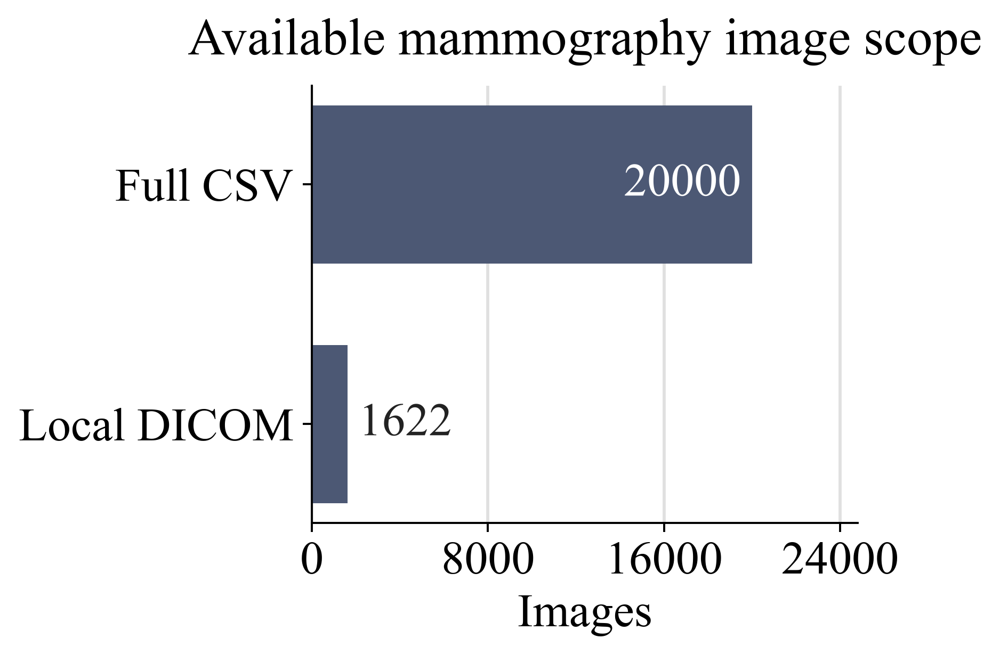

In [6]:
scope = json.loads((COHORT_TABLES / "cohort_scope.json").read_text())
scope_values = np.array([scope["official_images"], scope["local_images"]], dtype=float)
display_horizontal_bars(["Full CSV", "Local DICOM"], scope_values, title="Available mammography image scope", xlabel="Images", color="#4C5874")


### Figure 1.2. Frozen partitions


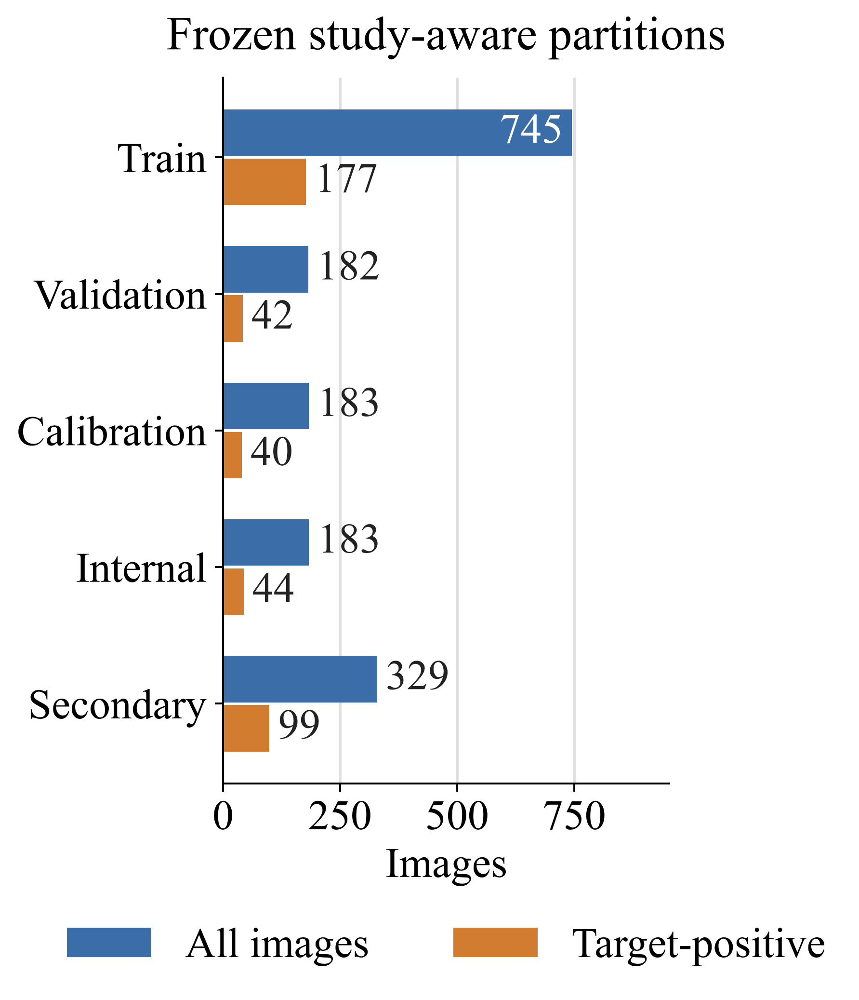

In [7]:
partition_order = [
    "train",
    "validation",
    "calibration",
    "locked_test",
    "secondary_source_test",
]
partition_labels = [
    "Train",
    "Validation",
    "Calibration",
    "Internal",
    "Secondary",
]
partition_frame = (
    dataset_summary.set_index("split")
    .loc[partition_order]
)
positions = np.arange(len(partition_frame))
all_values = partition_frame["images"].to_numpy(dtype=float)
positive_values = partition_frame["target_positive_images"].to_numpy(dtype=float)
maximum = float(all_values.max())

figure, axis = plt.subplots(
    figsize=(4.8, 5.8),
    constrained_layout=True,
)
all_bars = axis.barh(
    positions - 0.18,
    all_values,
    height=0.34,
    label="All images",
    color="#3B6EA8",
)
positive_bars = axis.barh(
    positions + 0.18,
    positive_values,
    height=0.34,
    label="Target-positive",
    color="#D17C2F",
)
for bars, values in [(all_bars, all_values), (positive_bars, positive_values)]:
    for bar, value in zip(bars, values):
        inside = value >= 0.72 * maximum
        axis.text(
            value - 0.025 * maximum if inside else value + 0.025 * maximum,
            bar.get_y() + bar.get_height() / 2,
            f"{int(value):,}",
            ha="right" if inside else "left",
            va="center",
            color="white" if inside else "#222222",
            fontsize=18,
        )
axis.set_xlim(0, maximum * 1.28)
axis.set_yticks(positions, partition_labels)
axis.invert_yaxis()
axis.set_xlabel("Images")
axis.set_title("Frozen study-aware partitions", pad=12)
axis.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    borderaxespad=0,
    ncol=2,
)
axis.xaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
clean_axis(axis, grid_axis="x")
display_scientific_figure(figure)

### Figure 1.3. Manufacturer support


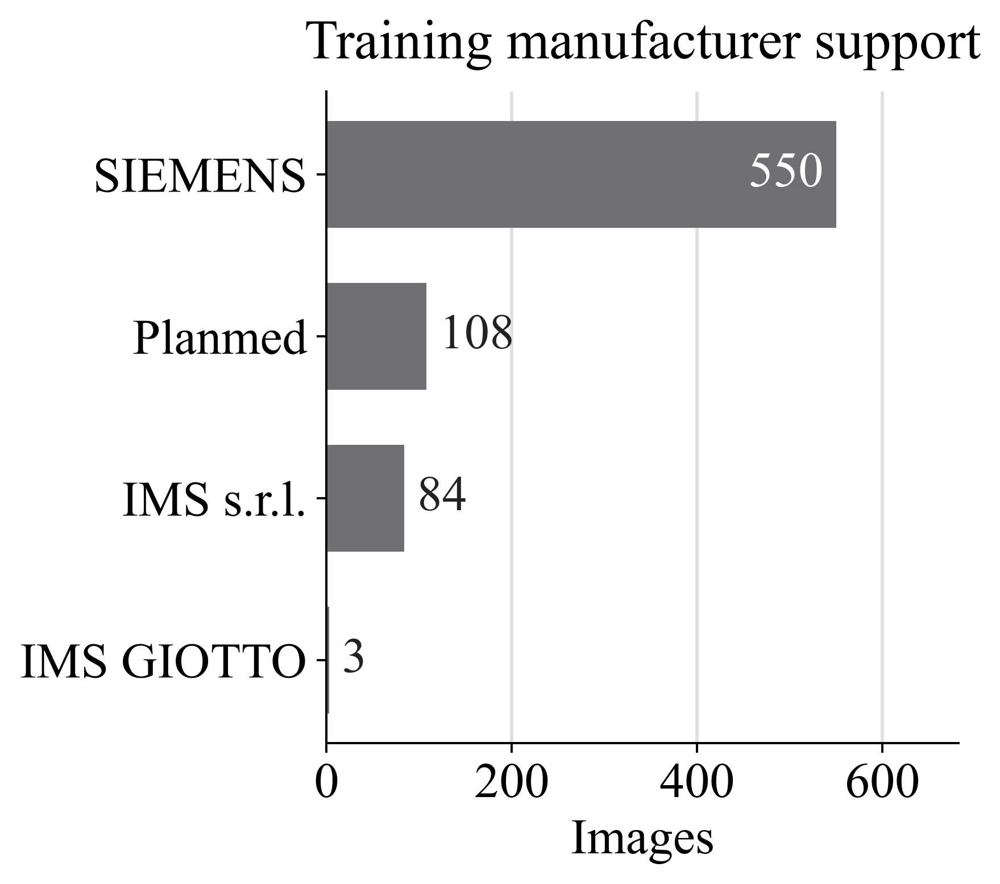

In [8]:
train_manifest = pd.read_csv(EDA_TABLES / "standard_dicom_features_train.csv")
manufacturer_counts = train_manifest["manufacturer"].value_counts()
manufacturer_labels = [
    "SIEMENS",
    "Planmed",
    "IMS s.r.l.",
    "IMS GIOTTO",
]
display_horizontal_bars(
    manufacturer_labels,
    manufacturer_counts.loc[
        ["SIEMENS", "Planmed", "IMS s.r.l.", "IMS GIOTTO S.p.A."]
    ].to_numpy(),
    title="Training manufacturer support",
    xlabel="Images",
    color="#6F6F73",
)

### Figure 1.4. Breast-density distribution


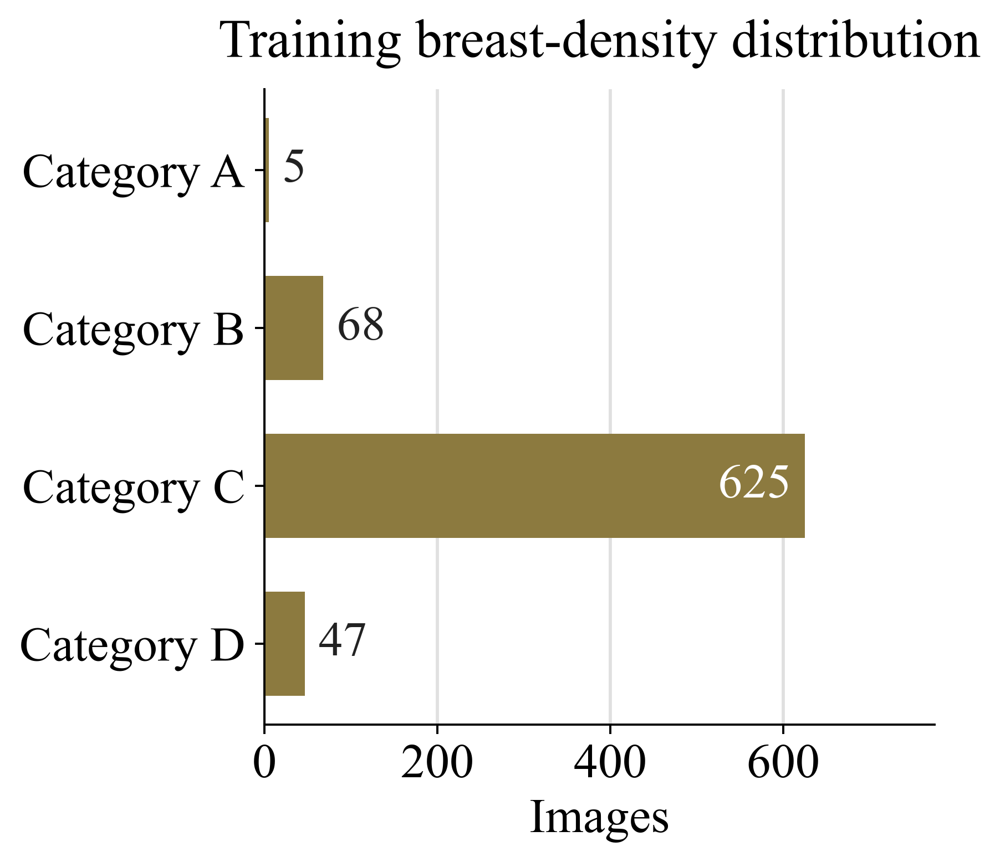

In [9]:
density_counts = train_manifest["breast_density"].value_counts().sort_index()
display_horizontal_bars(
    density_counts.index.str.replace("DENSITY ", "Category ", regex=False).tolist(),
    density_counts.to_numpy(),
    title="Training breast-density distribution",
    xlabel="Images",
    color="#8C7A3F",
)

### Figure 1.5. View distribution


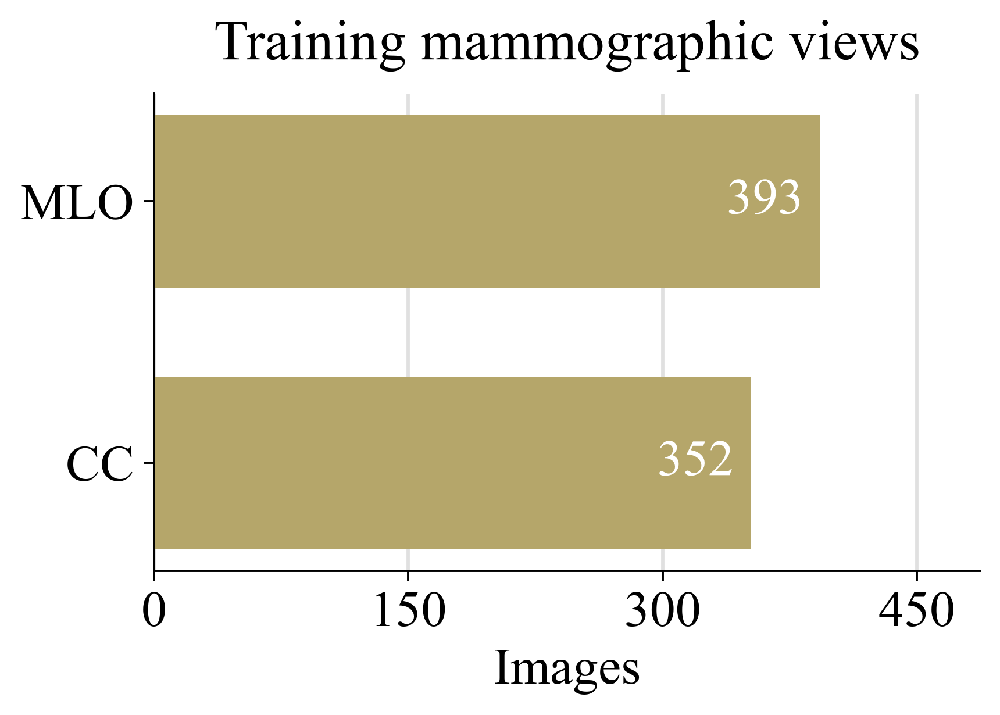

In [10]:
view_counts = train_manifest["view_position"].value_counts()
display_horizontal_bars(
    view_counts.index.tolist(),
    view_counts.to_numpy(),
    title="Training mammographic views",
    xlabel="Images",
    color="#B5A66A",
)

### Figure 1.6. Target bbox area


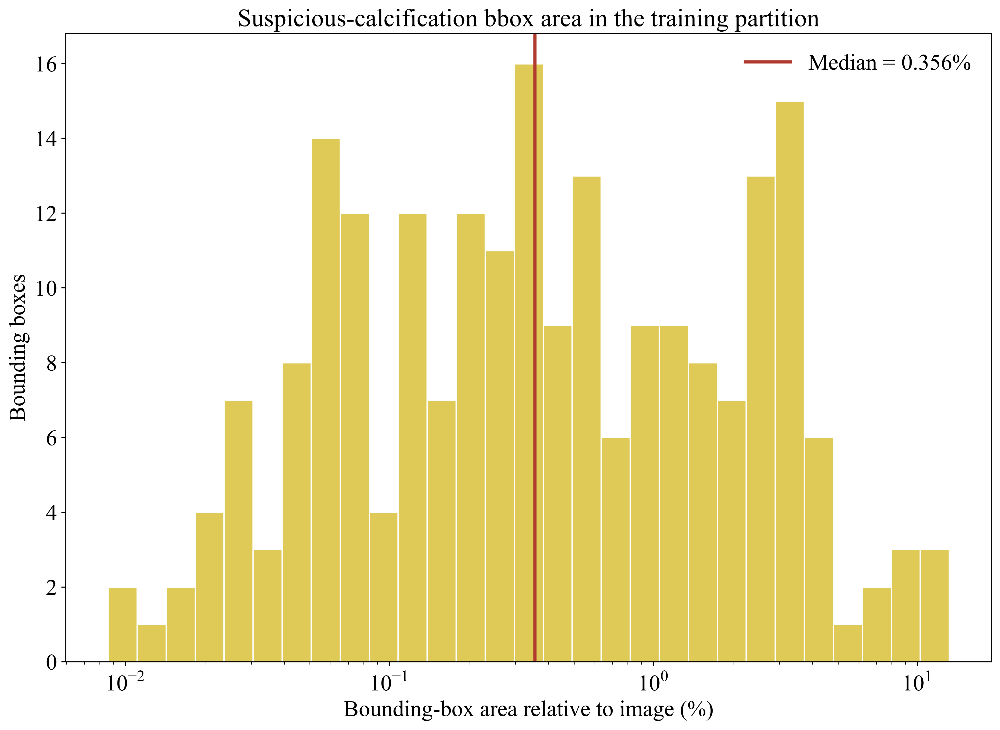

In [ ]:
display(Image(filename=str(resolve_figure("Figures/EDA/F06_train_target_bbox_area.png"))))


## 2. Standard DICOM rendering and exploratory image structure


### Table 2.1. DICOM header pathways


In [12]:
header_summary = pd.read_csv(
    EDA_TABLES / "standard_dicom_header_summary_train.csv"
)
for analysis_name, group in header_summary.groupby(
    "analysis",
    sort=False,
):
    show_table(
        group,
        caption=f"{analysis_name} support",
        columns=[
            "category",
            "count",
            "percentage",
        ],
        precision=2,
    )

category,count,percentage
12-bit,550,73.83
16-bit,195,26.17


category,count,percentage
MONOCHROME2,637,85.50
MONOCHROME1,108,14.50


category,count,percentage
present,550,73.83
absent,195,26.17


category,count,percentage
present,87,11.68
absent,658,88.32


### Figure 2.1. Standard DICOM render


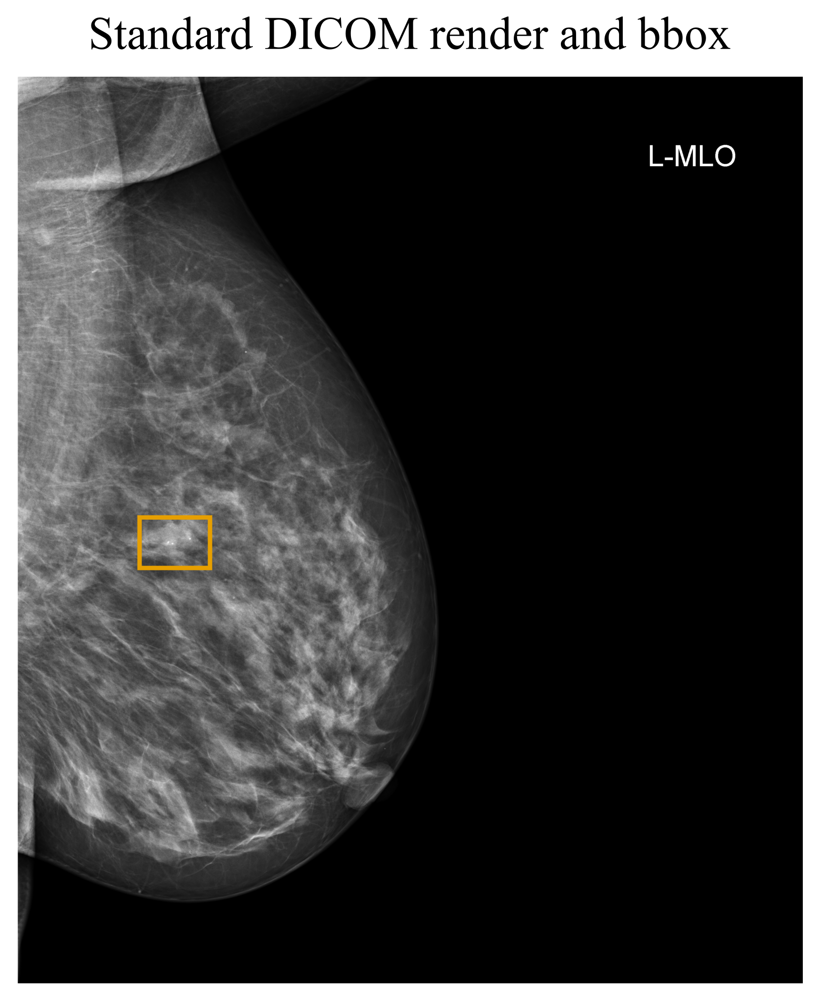

In [13]:
display_raster_panel(
    "Figures/EDA/F07_standard_dicom_render.png",
    crop_box=(30, 150, 3500, 4150),
    title="Standard DICOM render and bbox",
)

### Figure 2.2. Valid-pixel support


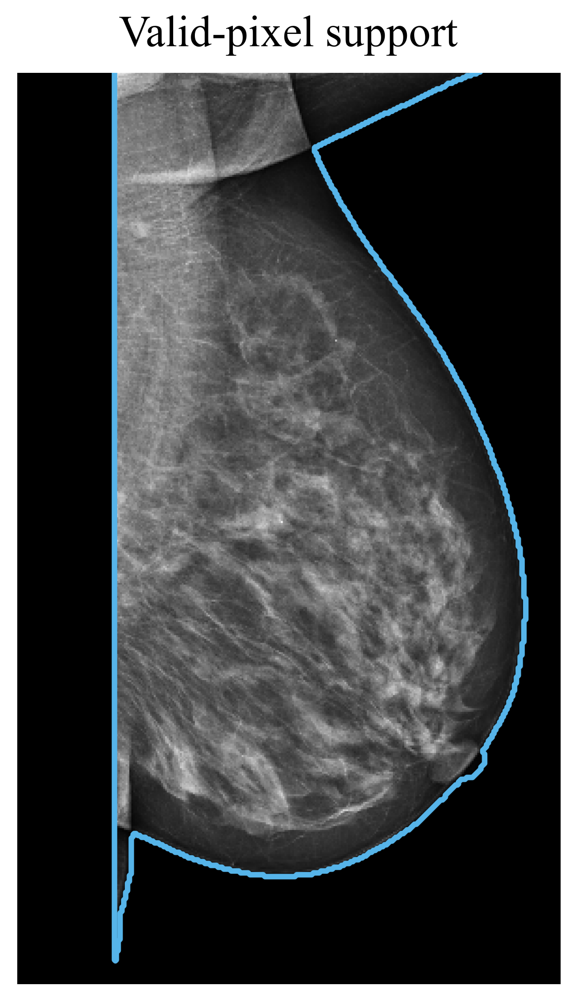

In [14]:
display_raster_panel(
    "Figures/EDA/F08_valid_pixel_support.png",
    crop_box=(30, 140, 1950, 3350),
    title="Valid-pixel support",
)

### Figure 2.3. Stored-pixel distribution


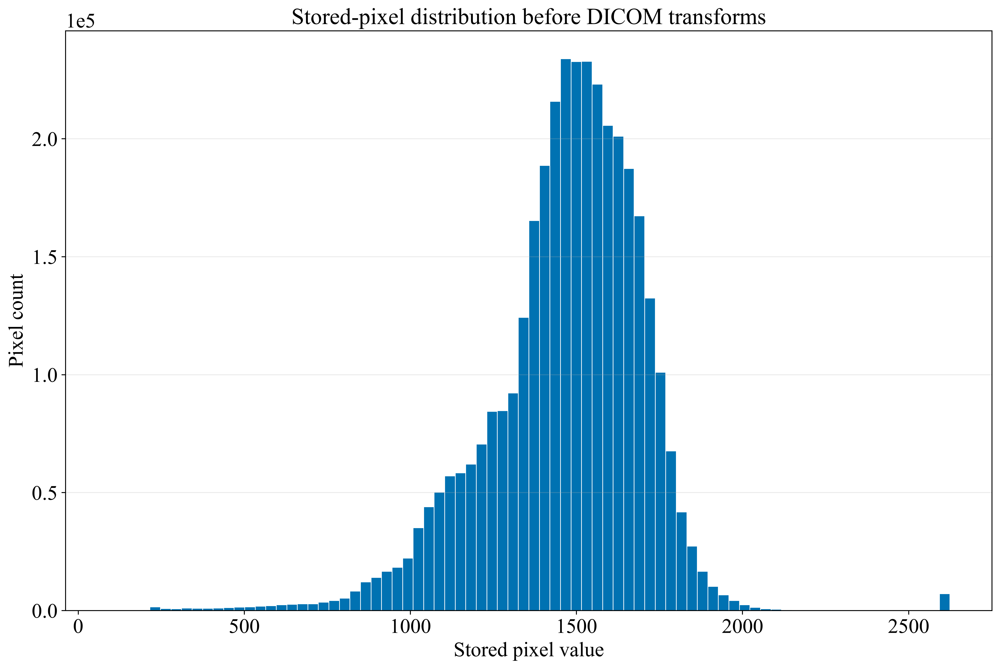

In [ ]:
display(Image(filename=str(resolve_figure("Figures/EDA/F09_stored_pixel_distribution.png"))))


### Figure 2.4. Standard presentation distribution


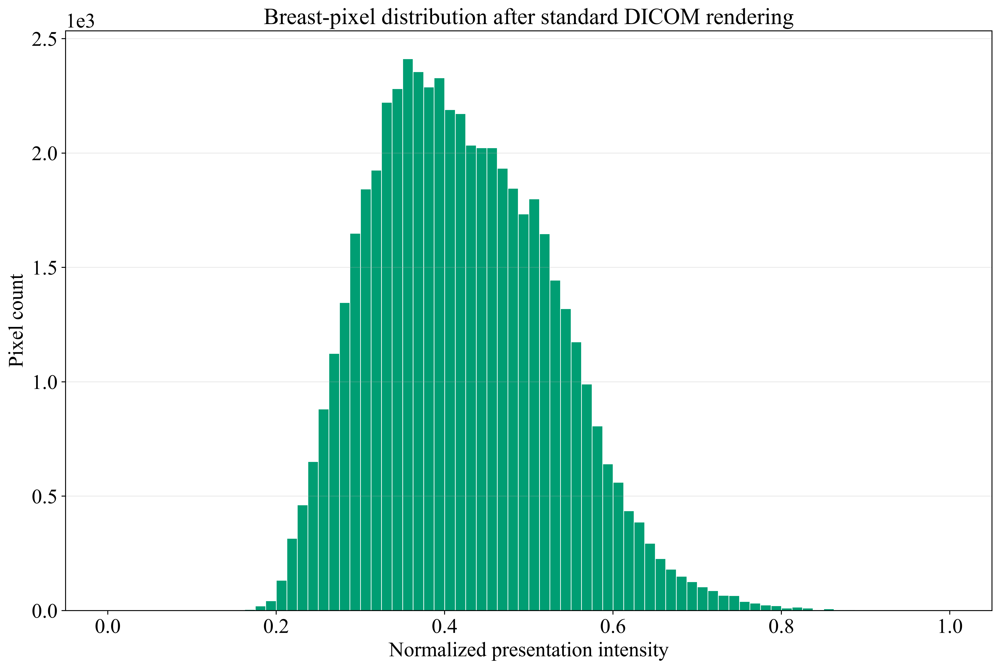

In [ ]:
display(Image(filename=str(resolve_figure("Figures/EDA/F10_standard_presentation_distribution.png"))))


### Figure 2.5. Standard DICOM pathways


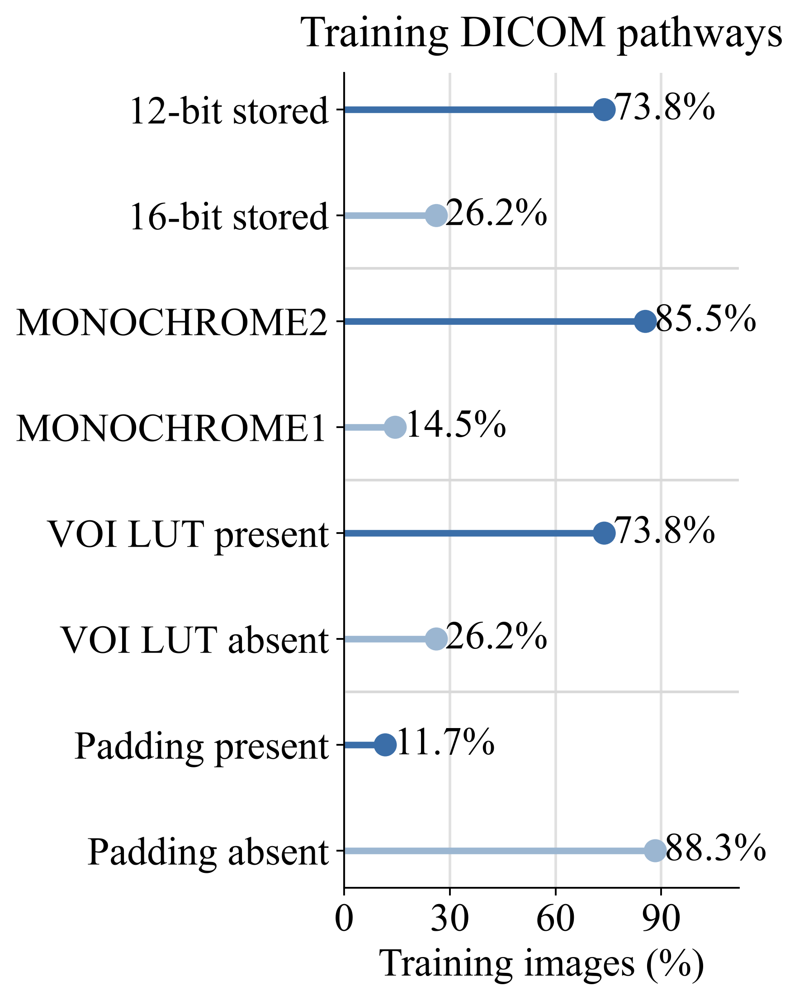

In [17]:
pathway_labels = [
    "12-bit stored",
    "16-bit stored",
    "MONOCHROME2",
    "MONOCHROME1",
    "VOI LUT present",
    "VOI LUT absent",
    "Padding present",
    "Padding absent",
]
pathway_values = header_summary["percentage"].to_numpy(dtype=float)
pathway_colors = [
    "#3B6EA8", "#9BB6D1",
    "#3B6EA8", "#9BB6D1",
    "#3B6EA8", "#9BB6D1",
    "#3B6EA8", "#9BB6D1",
]
positions = np.arange(len(pathway_labels))
figure, axis = plt.subplots(figsize=(4.8, 6.2), constrained_layout=True)
axis.hlines(positions, 0, pathway_values, color=pathway_colors, linewidth=3)
axis.scatter(pathway_values, positions, color=pathway_colors, s=90, zorder=3)
for position, value in zip(positions, pathway_values):
    axis.text(
        value + 2.5,
        position,
        f"{value:.1f}%",
        ha="left",
        va="center",
        fontsize=18,
    )
for boundary in [1.5, 3.5, 5.5]:
    axis.axhline(boundary, color="#D9D9D9", linewidth=1.2)
axis.set_xlim(0, 112)
axis.set_yticks(positions, pathway_labels)
axis.invert_yaxis()
axis.set_xlabel("Training images (%)")
axis.set_title("Training DICOM pathways", pad=12)
axis.xaxis.set_major_locator(MaxNLocator(nbins=4))
clean_axis(axis, grid_axis="x")
display_scientific_figure(figure)

### Figure 2.6. Study-feature correlation


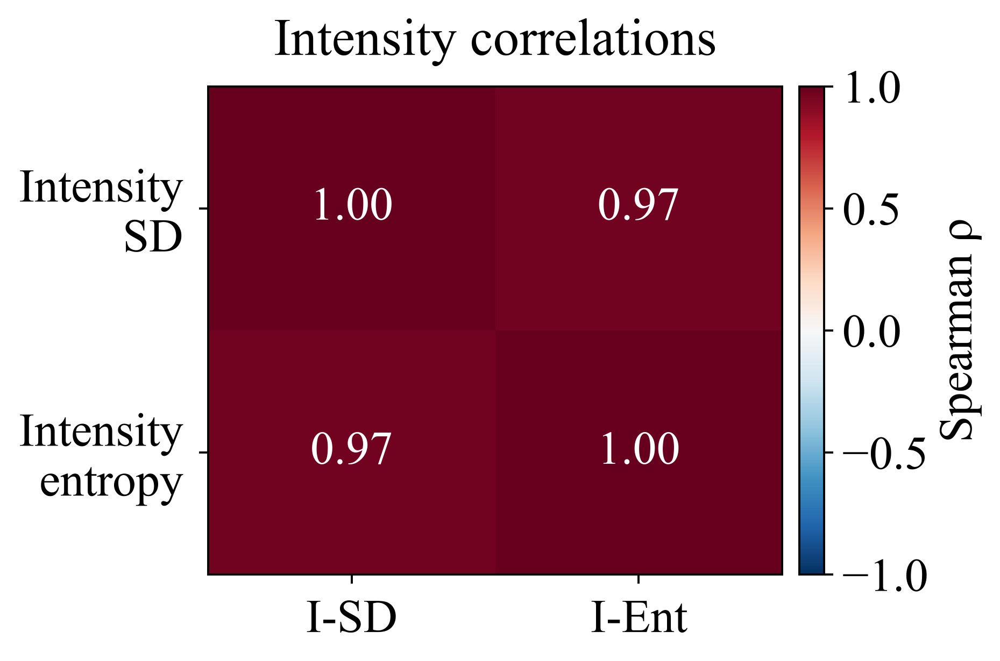

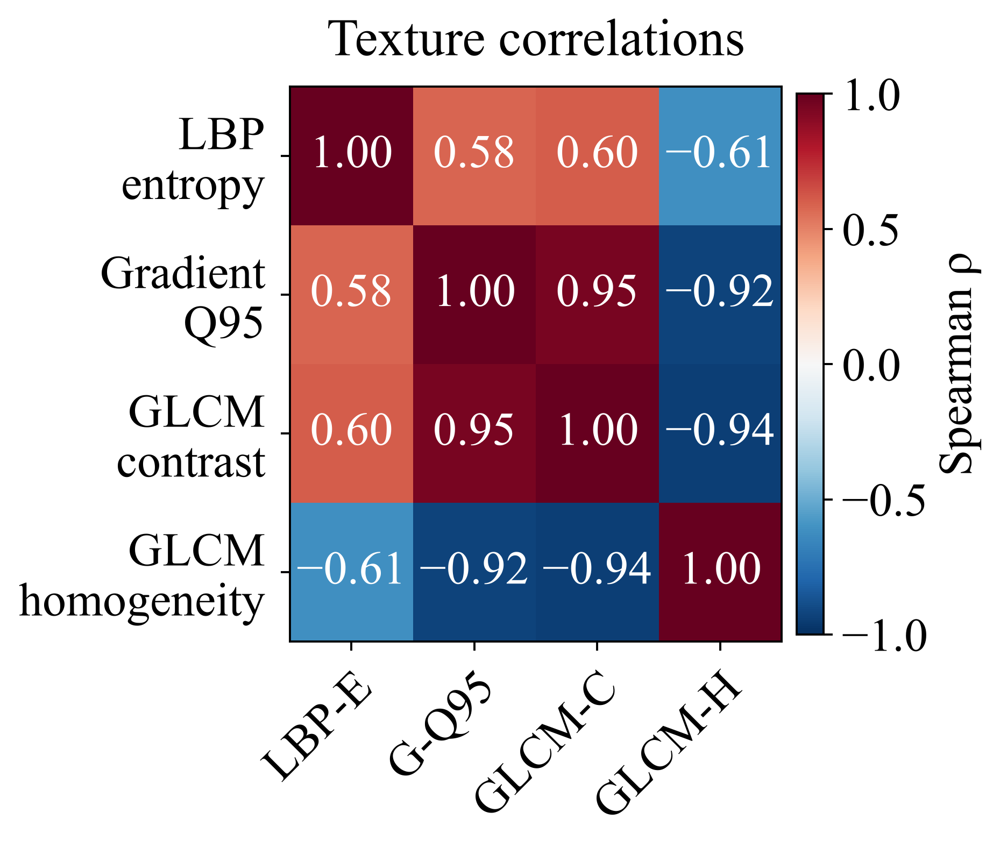

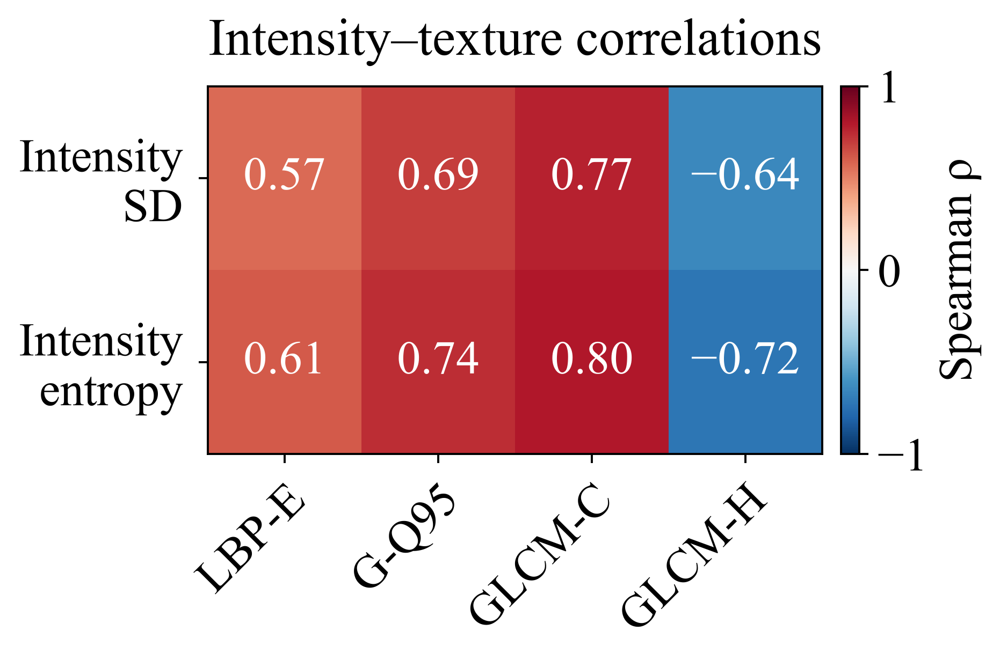

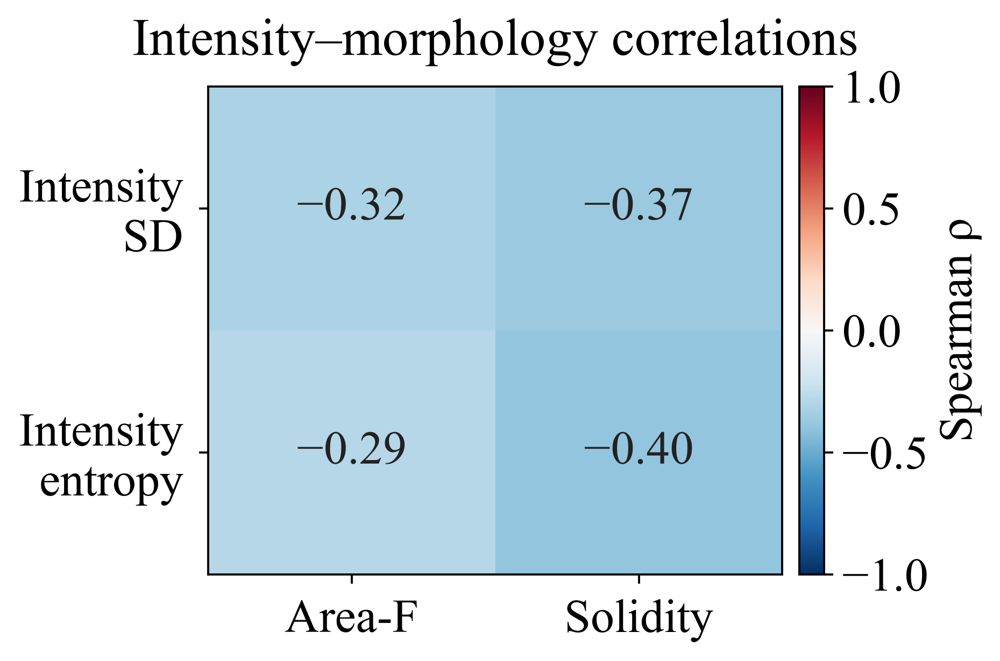

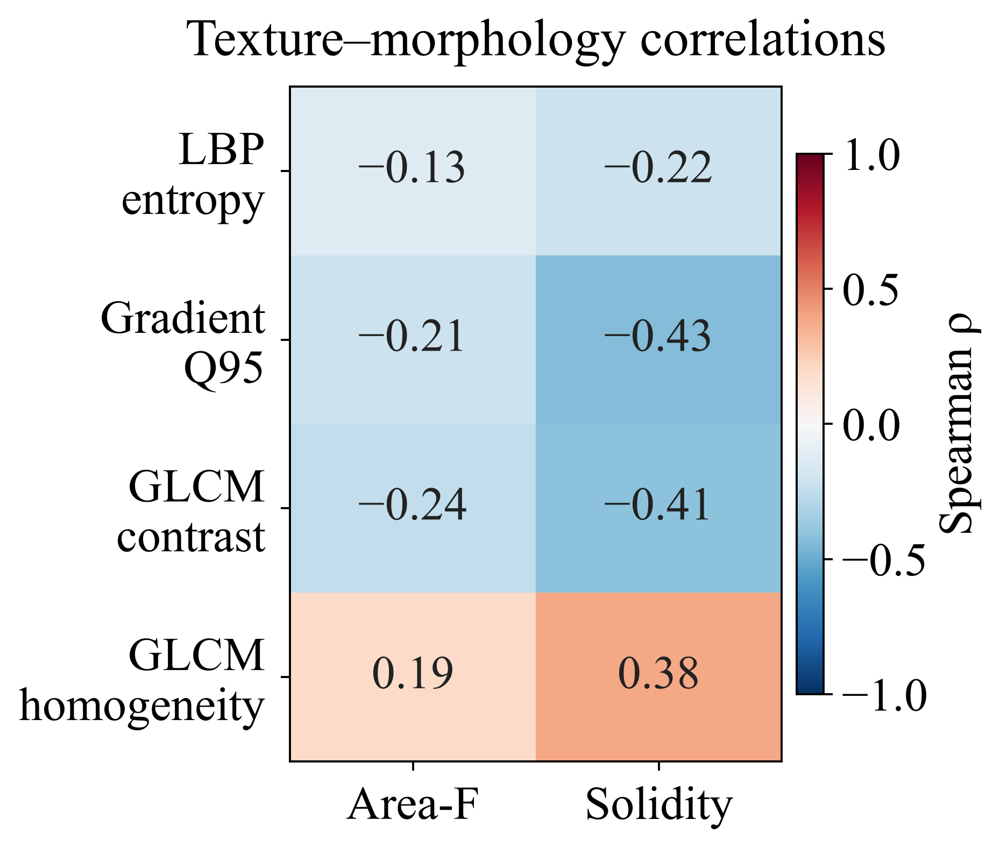

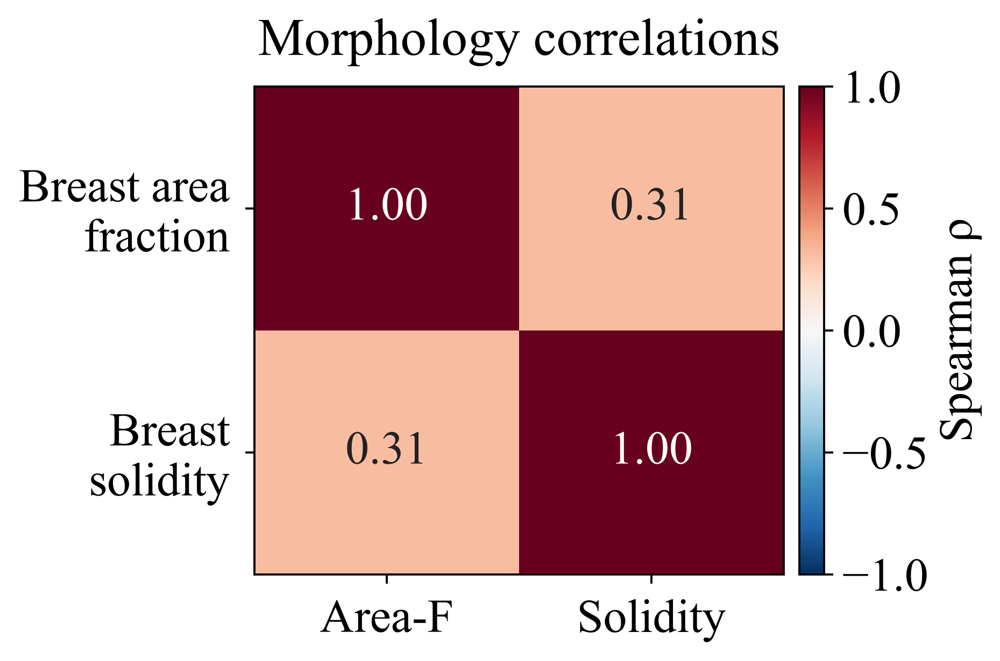

In [18]:
correlation_matrix = pd.read_csv(
    EDA_TABLES / "study_feature_spearman_correlation.csv",
    index_col=0,
)
feature_labels = {
    "intensity_std": "Intensity\nSD",
    "intensity_entropy": "Intensity\nentropy",
    "lbp_entropy": "LBP\nentropy",
    "gradient_q95": "Gradient\nQ95",
    "glcm_contrast": "GLCM\ncontrast",
    "glcm_homogeneity": "GLCM\nhomogeneity",
    "breast_area_fraction": "Breast area\nfraction",
    "breast_solidity": "Breast\nsolidity",
}
feature_column_labels = {
    "intensity_std": "I-SD",
    "intensity_entropy": "I-Ent",
    "lbp_entropy": "LBP-E",
    "gradient_q95": "G-Q95",
    "glcm_contrast": "GLCM-C",
    "glcm_homogeneity": "GLCM-H",
    "breast_area_fraction": "Area-F",
    "breast_solidity": "Solidity",
}
intensity_features = list(feature_labels)[:2]
texture_features = list(feature_labels)[2:6]
morphology_features = list(feature_labels)[6:]

def display_correlation_block(
    row_features: list[str],
    column_features: list[str],
    title: str,
) -> None:
    values = correlation_matrix.loc[row_features, column_features].to_numpy(dtype=float)
    height = max(3.4, 1.75 + 0.66 * len(row_features))
    figure, axis = plt.subplots(
        figsize=(5.2, height),
        constrained_layout=True,
    )
    matrix_image = axis.imshow(
        values,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        aspect="auto",
    )
    axis.set_xticks(
        np.arange(len(column_features)),
        [feature_column_labels[name] for name in column_features],
    )
    if len(column_features) >= 3:
        plt.setp(
            axis.get_xticklabels(),
            rotation=45,
            ha="right",
            rotation_mode="anchor",
        )
    axis.set_yticks(
        np.arange(len(row_features)),
        [feature_labels[name] for name in row_features],
    )
    for row_index in range(values.shape[0]):
        for column_index in range(values.shape[1]):
            value = values[row_index, column_index]
            axis.text(
                column_index,
                row_index,
                format_number(value, decimals=2),
                ha="center",
                va="center",
                color="white" if abs(value) >= 0.55 else "#222222",
                fontsize=18,
            )
    colorbar = figure.colorbar(
        matrix_image,
        ax=axis,
        fraction=0.055,
        pad=0.03,
    )
    colorbar.set_label("Spearman ρ", fontsize=18)
    colorbar.ax.tick_params(labelsize=18)
    axis.set_title(title, pad=12)
    axis.tick_params(labelsize=18, pad=6)
    display_scientific_figure(figure)

display_correlation_block(
    intensity_features,
    intensity_features,
    "Intensity correlations",
)
display_correlation_block(
    texture_features,
    texture_features,
    "Texture correlations",
)
display_correlation_block(
    intensity_features,
    texture_features,
    "Intensity–texture correlations",
)
display_correlation_block(
    intensity_features,
    morphology_features,
    "Intensity–morphology correlations",
)
display_correlation_block(
    texture_features,
    morphology_features,
    "Texture–morphology correlations",
)
display_correlation_block(
    morphology_features,
    morphology_features,
    "Morphology correlations",
)

### Figure 2.7. Exploratory feature effects


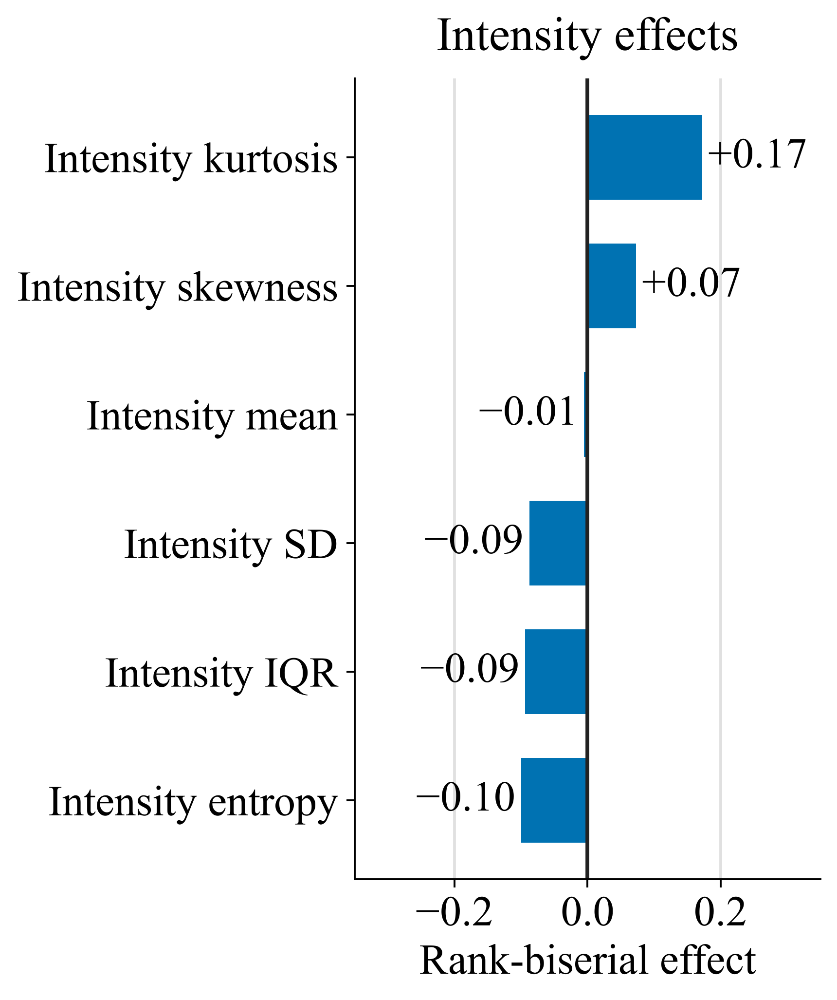

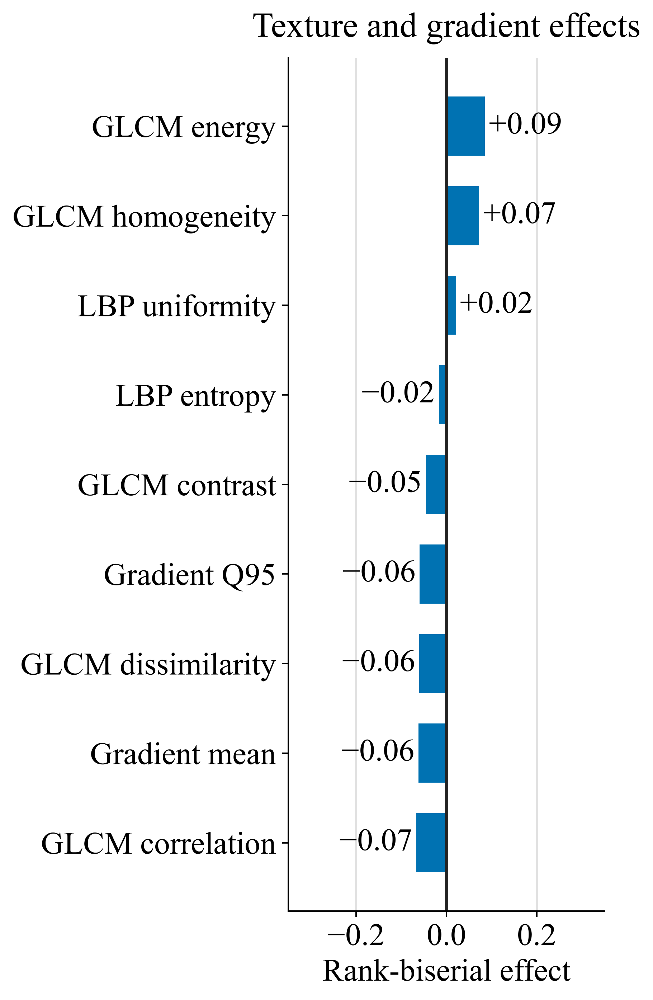

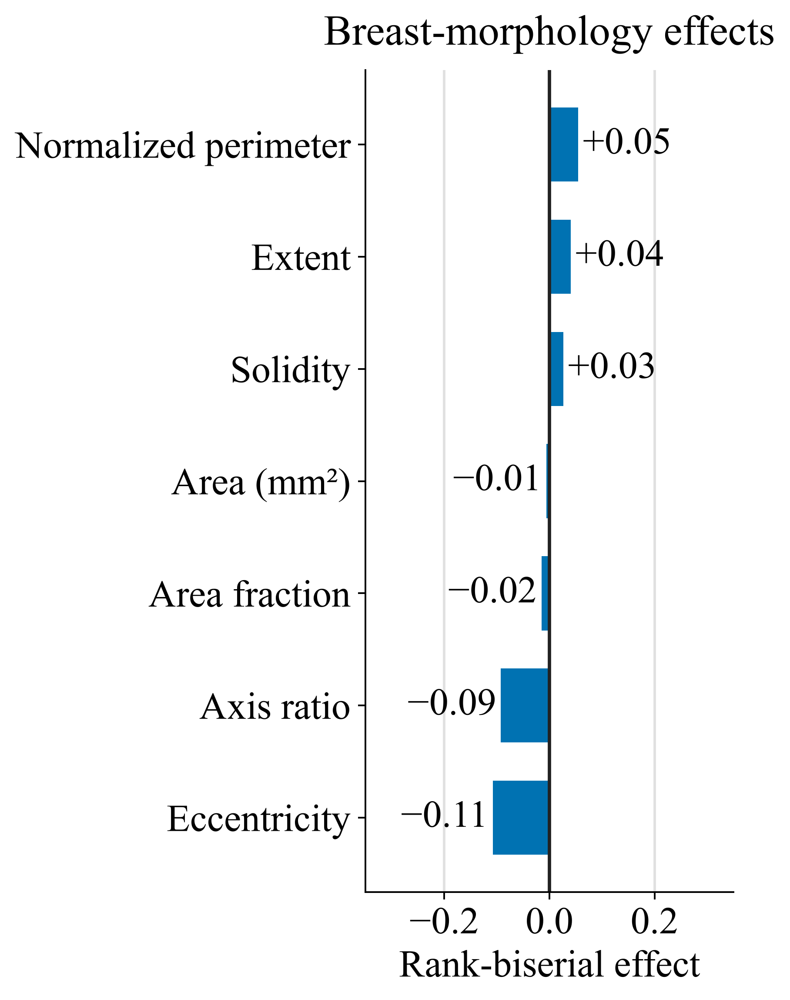

In [19]:
effect_frame = pd.read_csv(
    EDA_TABLES / "texture_group_statistics.csv"
).sort_values("rank_biserial")
effect_families = {
    "Intensity effects": effect_frame["feature"].str.startswith("intensity_"),
    "Texture and gradient effects": effect_frame["feature"].str.startswith(
        ("lbp_", "gradient_", "glcm_")
    ),
    "Breast-morphology effects": effect_frame["feature"].str.startswith("breast_"),
}
effect_labels = {
    "intensity_kurtosis": "Intensity kurtosis",
    "intensity_skew": "Intensity skewness",
    "intensity_mean": "Intensity mean",
    "intensity_std": "Intensity SD",
    "intensity_iqr": "Intensity IQR",
    "intensity_entropy": "Intensity entropy",
    "glcm_energy": "GLCM energy",
    "glcm_homogeneity": "GLCM homogeneity",
    "lbp_uniformity": "LBP uniformity",
    "lbp_entropy": "LBP entropy",
    "glcm_contrast": "GLCM contrast",
    "gradient_q95": "Gradient Q95",
    "glcm_dissimilarity": "GLCM dissimilarity",
    "gradient_mean": "Gradient mean",
    "glcm_correlation": "GLCM correlation",
    "breast_perimeter_normalized": "Normalized perimeter",
    "breast_extent": "Extent",
    "breast_solidity": "Solidity",
    "breast_area_mm2": "Area (mm²)",
    "breast_area_fraction": "Area fraction",
    "breast_axis_ratio": "Axis ratio",
    "breast_eccentricity": "Eccentricity",
}
for family_title, family_mask in effect_families.items():
    family = effect_frame.loc[family_mask].sort_values("rank_biserial")
    labels = family["feature"].map(effect_labels)
    assert labels.notna().all()
    values = family["rank_biserial"].to_numpy(dtype=float)
    limit = max(0.35, float(np.abs(values).max()) + 0.15)
    positions = np.arange(len(family))
    height = max(3.6, 1.55 + 0.70 * len(family))
    figure, axis = plt.subplots(
        figsize=(4.8, height),
        constrained_layout=True,
    )
    bars = axis.barh(positions, values, color="#0072B2", height=0.66)
    axis.axvline(0, color="#222222", linewidth=1.6)
    axis.set_yticks(positions, labels)
    axis.set_xlim(-limit, limit)
    for bar, value in zip(bars, values):
        offset = 0.025 * limit
        axis.text(
            value + offset if value >= 0 else value - offset,
            bar.get_y() + bar.get_height() / 2,
            format_signed(value, decimals=2),
            ha="left" if value >= 0 else "right",
            va="center",
            fontsize=18,
        )
    axis.set_xlabel("Rank-biserial effect")
    axis.set_title(family_title, pad=12)
    axis.xaxis.set_major_locator(MaxNLocator(nbins=4))
    clean_axis(axis, grid_axis="x")
    display_scientific_figure(figure)

### Figure 2.8. Top-ranked exploratory feature


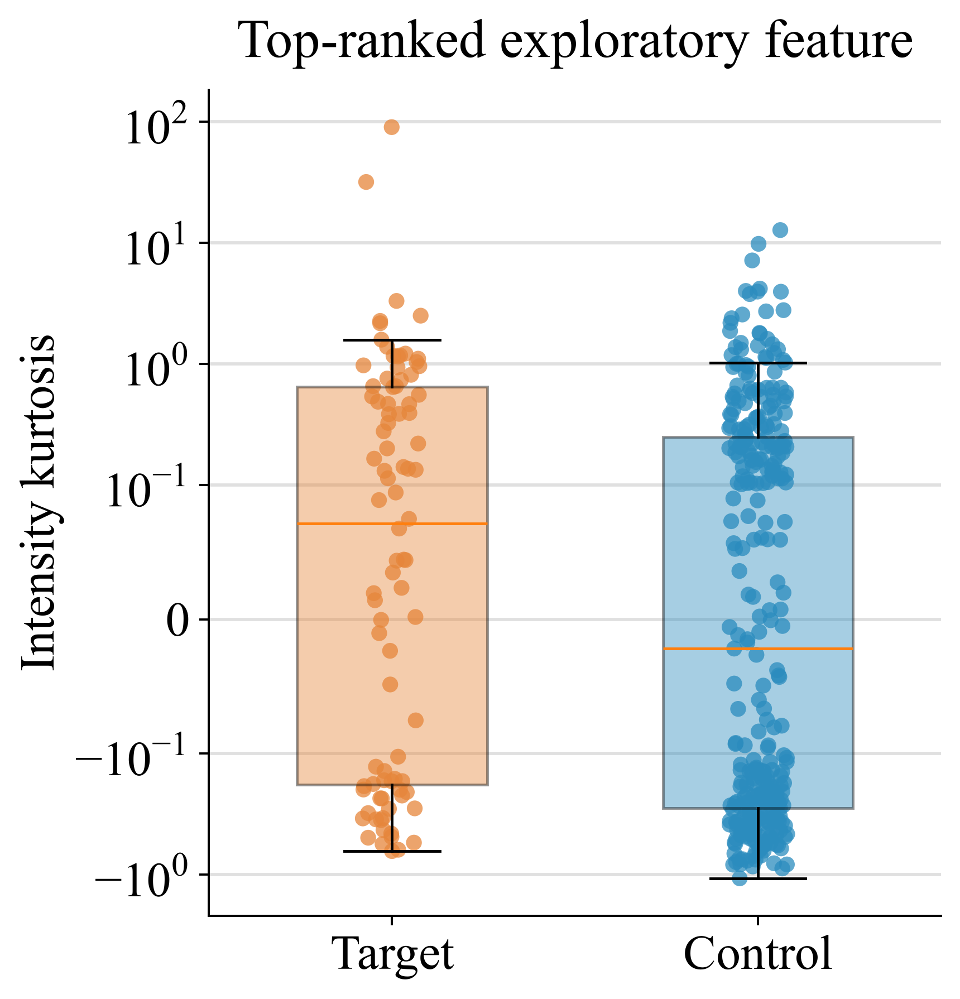

In [20]:
feature_values = pd.read_csv(
    EDA_TABLES / "top_ranked_feature_study_values.csv"
)
group_order = ["Target study", "Other-finding control study"]
group_labels = ["Target", "Control"]
group_colors = ["#E6863B", "#2B8CBE"]
group_arrays = [
    feature_values.loc[feature_values["group"].eq(group), "value"].to_numpy()
    for group in group_order
]
figure, axis = plt.subplots(figsize=(4.8, 5.0), constrained_layout=True)
boxplot = axis.boxplot(
    group_arrays,
    positions=np.arange(len(group_order)),
    widths=0.52,
    patch_artist=True,
    showfliers=False,
)
for patch, color in zip(boxplot["boxes"], group_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.42)
rng = np.random.default_rng(2026)
for position, (values, color) in enumerate(zip(group_arrays, group_colors)):
    jitter = rng.uniform(-0.08, 0.08, size=len(values))
    axis.scatter(
        position + jitter,
        values,
        s=34,
        color=color,
        alpha=0.75,
        edgecolors="none",
    )
axis.set_yscale("symlog", linthresh=0.1)
axis.set_xticks(np.arange(len(group_order)), group_labels)
axis.set_ylabel("Intensity kurtosis")
axis.set_title("Top-ranked exploratory feature", pad=12)
clean_axis(axis, grid_axis="y")
display_scientific_figure(figure)

### Table 2.2. Study-level feature correlations


In [21]:
feature_correlation = pd.read_csv(
    EDA_TABLES / "study_feature_spearman_correlation.csv",
    index_col=0,
)
correlation_view = feature_correlation.reset_index(
    names="feature"
)
show_table(
    correlation_view,
    caption="Study-level Spearman correlation matrix",
    precision=3,
)

feature,intensity_std,intensity_entropy,lbp_entropy,gradient_q95,glcm_contrast,glcm_homogeneity,breast_area_fraction,breast_solidity
intensity_std,1.000,0.966,0.569,0.695,0.770,-0.642,-0.318,-0.374
intensity_entropy,0.966,1.000,0.614,0.738,0.801,-0.721,-0.285,-0.398
lbp_entropy,0.569,0.614,1.000,0.582,0.605,-0.613,-0.129,-0.219
gradient_q95,0.695,0.738,0.582,1.000,0.949,-0.923,-0.215,-0.431
glcm_contrast,0.770,0.801,0.605,0.949,1.000,-0.944,-0.243,-0.412
glcm_homogeneity,-0.642,-0.721,-0.613,-0.923,-0.944,1.000,0.194,0.384
breast_area_fraction,-0.318,-0.285,-0.129,-0.215,-0.243,0.194,1.000,0.310
breast_solidity,-0.374,-0.398,-0.219,-0.431,-0.412,0.384,0.310,1.000


### Table 2.3. Exploratory feature statistics


In [22]:
feature_statistics = pd.read_csv(
    EDA_TABLES / "texture_group_statistics.csv"
)

feature_families = {
    "Intensity": feature_statistics["feature"].str.startswith(
        "intensity_"
    ),
    "Texture and gradient": feature_statistics["feature"].str.startswith(
        ("glcm_", "lbp_", "gradient_")
    ),
    "Breast morphology": feature_statistics["feature"].str.startswith(
        "breast_"
    ),
}

descriptive_columns = [
    "feature",
    "target_studies",
    "control_studies",
    "target_median",
    "control_median",
    "median_difference",
]
inference_columns = [
    "feature",
    "median_difference_ci_lower",
    "median_difference_ci_upper",
    "rank_biserial",
    "p_value",
    "q_value_bh",
    "exploratory_fdr_0_05",
]

for family_name, family_mask in feature_families.items():
    family_frame = feature_statistics.loc[family_mask]
    show_table(
        family_frame,
        caption=f"{family_name}: descriptive estimates",
        columns=descriptive_columns,
        precision=4,
    )
    show_table(
        family_frame,
        caption=f"{family_name}: exploratory inference",
        columns=inference_columns,
        precision=4,
    )

feature,target_studies,control_studies,target_median,control_median,median_difference
intensity_kurtosis,88,313,0.0711,-0.0218,0.0929
intensity_std,88,313,0.0974,0.0993,-0.0019
intensity_skew,88,313,0.3950,0.3500,0.0450
intensity_iqr,88,313,0.1325,0.1337,-0.0012
intensity_entropy,88,313,4.6181,4.6488,-0.0307
intensity_mean,88,313,0.4776,0.4761,0.0015


feature,median_difference_ci_lower,median_difference_ci_upper,rank_biserial,p_value,q_value_bh,exploratory_fdr_0_05
intensity_kurtosis,-0.0042,0.2279,0.1725,0.0134,0.2956,False
intensity_std,-0.0064,0.0017,-0.0876,0.2091,0.6700,False
intensity_skew,-0.0380,0.1341,0.0730,0.2952,0.6700,False
intensity_iqr,-0.0080,0.0038,-0.0936,0.1798,0.6700,False
intensity_entropy,-0.0679,0.0244,-0.0999,0.1522,0.6700,False
intensity_mean,-0.0179,0.0224,-0.0054,0.9382,0.9382,False


feature,target_studies,control_studies,target_median,control_median,median_difference
glcm_dissimilarity,88,313,1.9545,1.9659,-0.0114
gradient_q95,88,313,0.0968,0.0990,-0.0022
gradient_mean,88,313,0.0448,0.0451,-0.0003
glcm_correlation,88,313,0.6215,0.6406,-0.0191
glcm_energy,88,313,0.1156,0.1139,0.0017
glcm_homogeneity,88,313,0.4075,0.4056,0.0018
glcm_contrast,88,313,7.0200,7.1679,-0.1480
lbp_uniformity,88,313,0.1082,0.1080,0.0002
lbp_entropy,88,313,3.2708,3.2718,-0.0010


feature,median_difference_ci_lower,median_difference_ci_upper,rank_biserial,p_value,q_value_bh,exploratory_fdr_0_05
glcm_dissimilarity,-0.0834,0.0681,-0.0602,0.3884,0.6700,False
gradient_q95,-0.0062,0.0034,-0.0593,0.3959,0.6700,False
gradient_mean,-0.0025,0.0014,-0.0619,0.3748,0.6700,False
glcm_correlation,-0.0315,0.0016,-0.0664,0.3411,0.6700,False
glcm_energy,-0.0026,0.0058,0.0854,0.2211,0.6700,False
glcm_homogeneity,-0.0083,0.0120,0.0726,0.2981,0.6700,False
glcm_contrast,-0.5637,0.5739,-0.0454,0.5156,0.7562,False
lbp_uniformity,-0.0004,0.0006,0.0213,0.7607,0.9128,False
lbp_entropy,-0.0034,0.0027,-0.0169,0.8087,0.9128,False


feature,target_studies,control_studies,target_median,control_median,median_difference
breast_eccentricity,88,313,0.9135,0.9212,-0.0077
breast_axis_ratio,88,313,2.6653,2.8019,-0.1366
breast_perimeter_normalized,88,313,6.8575,6.7352,0.1223
breast_extent,88,313,0.5940,0.5793,0.0146
breast_solidity,88,313,0.7816,0.7807,0.0009
breast_area_fraction,88,313,0.5037,0.4837,0.0200
breast_area_mm2,88,313,6180.2472,6201.6516,-21.4044


feature,median_difference_ci_lower,median_difference_ci_upper,rank_biserial,p_value,q_value_bh,exploratory_fdr_0_05
breast_eccentricity,-0.0198,0.0004,-0.1076,0.1230,0.6700,False
breast_axis_ratio,-0.2718,0.0980,-0.0923,0.1860,0.6700,False
breast_perimeter_normalized,-0.0744,0.4107,0.0549,0.4316,0.6782,False
breast_extent,-0.0124,0.0318,0.0409,0.5582,0.7675,False
breast_solidity,-0.0165,0.0209,0.0266,0.7028,0.9095,False
breast_area_fraction,-0.0304,0.0443,-0.0150,0.8298,0.9128,False
breast_area_mm2,-771.5748,565.2047,-0.0058,0.9340,0.9382,False


## 3. Proposed-model development and ablation evidence


### Table 3.1. Selected development checkpoints by variant and seed


In [23]:
selected_by_seed = pd.read_csv(
    MODEL_TABLES / "bcrf_selected_by_seed.csv"
)

selected_columns = [
    "seed",
    "selected_epoch",
    "penalized_iou",
    "matched_iou",
    "peak_in_box",
    "box_recall_0_1",
    "count_accuracy",
    "positive_studies",
]

for variant_name, group in selected_by_seed.groupby(
    "variant",
    sort=False,
):
    show_table(
        group,
        caption=f"{variant_name}: selected development checkpoints",
        columns=selected_columns,
        precision=4,
    )

seed,selected_epoch,penalized_iou,matched_iou,peak_in_box,box_recall_0_1,count_accuracy,positive_studies
17,4,0.2558,0.2928,0.6667,0.5455,0.7692,22
29,3,0.2034,0.2305,0.6591,0.5795,0.7692,22
43,6,0.2339,0.2746,0.7045,0.5455,0.1758,22


seed,selected_epoch,penalized_iou,matched_iou,peak_in_box,box_recall_0_1,count_accuracy,positive_studies
17,6,0.2372,0.2772,0.7500,0.6136,0.7692,22
29,3,0.1959,0.2272,0.5909,0.5492,0.7692,22
43,6,0.2374,0.2745,0.6364,0.6402,0.3187,22


seed,selected_epoch,penalized_iou,matched_iou,peak_in_box,box_recall_0_1,count_accuracy,positive_studies
17,5,0.2065,0.2375,0.7045,0.4924,0.7692,22
29,4,0.1723,0.2081,0.7045,0.4432,0.7692,22
43,5,0.2461,0.2748,0.7273,0.5682,0.1758,22


seed,selected_epoch,penalized_iou,matched_iou,peak_in_box,box_recall_0_1,count_accuracy,positive_studies
17,5,0.2399,0.2785,0.7045,0.5795,0.7692,22
29,3,0.2046,0.2499,0.6818,0.4886,0.7692,22
43,6,0.2468,0.2881,0.7045,0.5455,0.1758,22


seed,selected_epoch,penalized_iou,matched_iou,peak_in_box,box_recall_0_1,count_accuracy,positive_studies
17,4,0.2475,0.2820,0.6894,0.6894,0.7692,22
29,3,0.2088,0.2452,0.6818,0.5833,0.7692,22
43,5,0.2149,0.2557,0.6364,0.5795,0.1758,22


### Table 3.2. BCRF ablation summary


In [24]:
ablation_summary = pd.read_csv(
    MODEL_TABLES / "bcrf_ablation_summary.csv"
).sort_values(
    "penalized_iou_mean",
    ascending=False,
)

show_table(
    ablation_summary,
    caption="BCRF development-ablation summary across three seeds",
    columns=[
        "variant",
        "penalized_iou_mean",
        "penalized_iou_sd",
        "matched_iou_mean",
        "peak_in_box_mean",
        "box_recall_mean",
    ],
    precision=4,
    highlight_max=[
        "penalized_iou_mean",
        "matched_iou_mean",
        "peak_in_box_mean",
        "box_recall_mean",
    ],
)

variant,penalized_iou_mean,penalized_iou_sd,matched_iou_mean,peak_in_box_mean,box_recall_mean
full_bcrf,0.2310,0.0263,0.2660,0.6768,0.5568
uniform_fusion,0.2304,0.0227,0.2722,0.6970,0.5379
equal_balance,0.2237,0.0208,0.2610,0.6692,0.6174
no_morphology,0.2235,0.0239,0.2596,0.6591,0.6010
no_center_rank,0.2083,0.0369,0.2401,0.7121,0.5013


### Table 3.3. Paired ablation contrasts


In [25]:
ablation_contrasts = pd.read_csv(
    MODEL_TABLES / "bcrf_paired_ablation_contrasts.csv"
)

show_table(
    ablation_contrasts,
    caption="Paired development contrasts: full BCRF minus ablation",
    columns=[
        "contrast",
        "positive_studies",
        "mean_delta",
        "ci95_low",
        "ci95_high",
        "wilcoxon_p",
        "holm_p",
        "analysis_role",
    ],
    precision=4,
)

contrast,positive_studies,mean_delta,ci95_low,ci95_high,wilcoxon_p,holm_p,analysis_role
full_bcrf - no_morphology,22,0.0075,-0.0286,0.0453,0.4873,1.0000,exploratory development
full_bcrf - no_center_rank,22,0.0227,-0.0193,0.0672,0.2314,0.9256,exploratory development
full_bcrf - uniform_fusion,22,0.0006,-0.0398,0.0413,0.5380,1.0000,exploratory development
full_bcrf - equal_balance,22,0.0073,-0.0297,0.0429,0.4119,1.0000,exploratory development


### Table 3.4. Presence and uncertainty diagnostics by seed


In [26]:
presence_uncertainty = pd.read_csv(
    MODEL_TABLES / "bcrf_presence_uncertainty_by_seed.csv"
)

for variant_name, group in presence_uncertainty.groupby(
    "variant",
    sort=False,
):
    show_table(
        group,
        caption=f"{variant_name}: secondary diagnostics by seed",
        columns=[
            "seed",
            "presence_auroc",
            "presence_auprc",
            "system_count_accuracy",
            "uncertainty_error_spearman",
        ],
        precision=4,
    )

seed,presence_auroc,presence_auprc,system_count_accuracy,uncertainty_error_spearman
17,0.5838,0.3168,0.7692,0.1607
29,0.5845,0.3835,0.7692,0.1665
43,0.5000,0.2308,0.1758,0.0168


seed,presence_auroc,presence_auprc,system_count_accuracy,uncertainty_error_spearman
17,0.6024,0.3220,0.7692,0.2378
29,0.5325,0.2498,0.7692,0.1036
43,0.5384,0.3070,0.1758,-0.0366


seed,presence_auroc,presence_auprc,system_count_accuracy,uncertainty_error_spearman
17,0.5129,0.3532,0.7692,0.0675
29,0.6205,0.3325,0.7692,0.4129
43,0.5386,0.2639,0.1758,-0.0629


seed,presence_auroc,presence_auprc,system_count_accuracy,uncertainty_error_spearman
17,0.5251,0.2429,0.7692,0.4193
29,0.5713,0.3576,0.7692,0.0293
43,0.5009,0.3137,0.3187,-0.3086


seed,presence_auroc,presence_auprc,system_count_accuracy,uncertainty_error_spearman
17,0.5325,0.3137,0.7692,0.0954
29,0.5010,0.2694,0.7692,0.0756
43,0.5383,0.2459,0.1758,-0.2282


### Figure 3.1. BCRF development trajectory


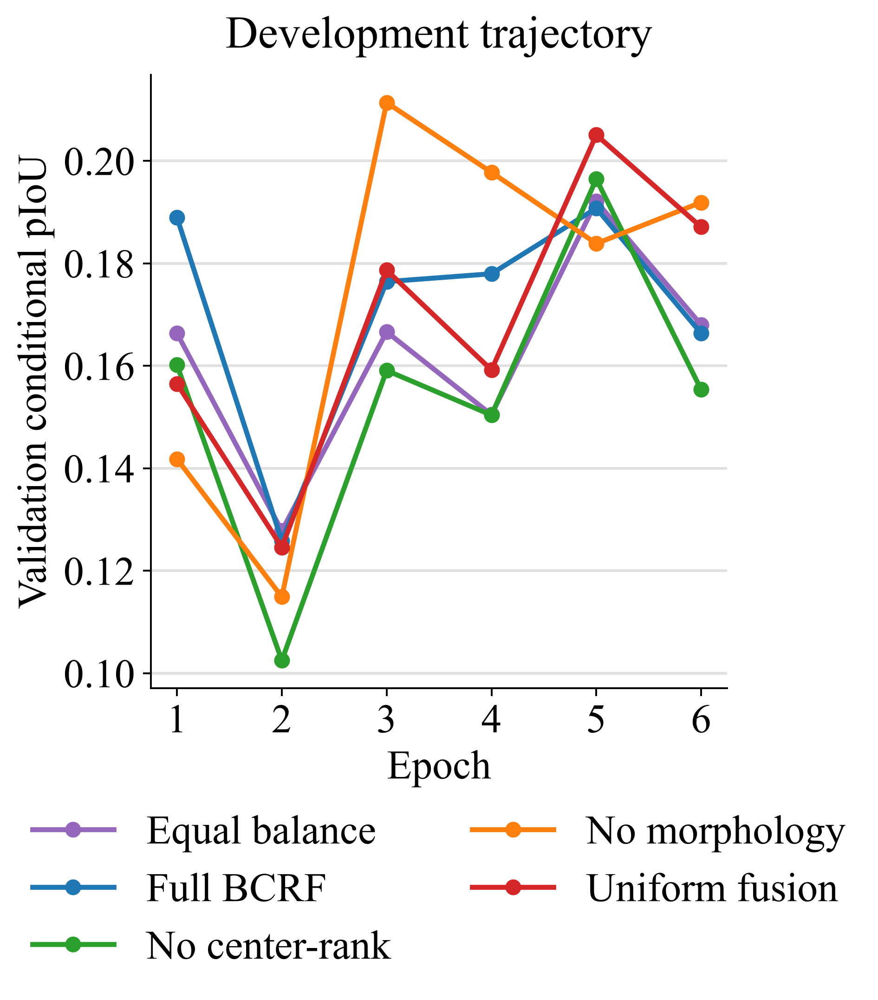

In [27]:
training_history = pd.read_csv(MODEL_TABLES / "bcrf_training_history.csv")
trajectory = (
    training_history.groupby(["variant", "epoch"], as_index=False)
    .agg(
        mean_pIoU=("validation_penalized_iou", "mean"),
        sd_pIoU=("validation_penalized_iou", "std"),
    )
)
variant_labels = {
    "full_bcrf": "Full BCRF",
    "no_morphology": "No morphology",
    "no_center_rank": "No center-rank",
    "uniform_fusion": "Uniform fusion",
    "equal_balance": "Equal balance",
}
variant_colors = dict(
    zip(variant_labels, mpl.colormaps["tab10"].colors[:5])
)
figure, axis = plt.subplots(figsize=(5.2, 6.0), constrained_layout=True)
for variant, variant_frame in trajectory.groupby("variant", sort=False):
    color = variant_colors[variant]
    axis.plot(
        variant_frame["epoch"],
        variant_frame["mean_pIoU"],
        marker="o",
        linewidth=2.2,
        color=color,
        label=variant_labels[variant],
    )
axis.set_xlabel("Epoch")
axis.set_ylabel("Validation conditional pIoU")
axis.set_title("Development trajectory", pad=12)
axis.xaxis.set_major_locator(MaxNLocator(integer=True))
axis.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    borderaxespad=0,
    ncol=2,
)
clean_axis(axis, grid_axis="y")
display_scientific_figure(figure)

### Figure 3.2. BCRF development ablation


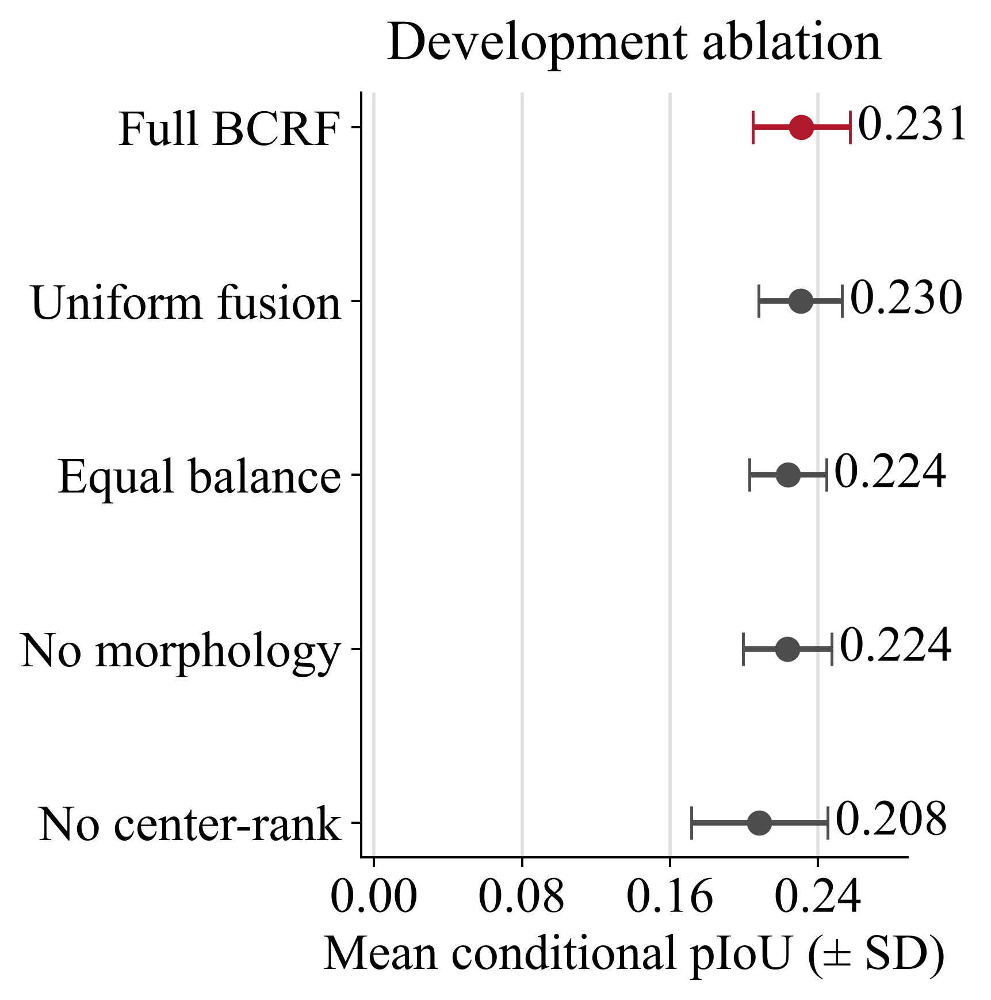

In [28]:
ablation_plot = ablation_summary.copy()
ablation_plot["label"] = ablation_plot["variant"].map(variant_labels)
ablation_plot["low"] = (
    ablation_plot["penalized_iou_mean"] - ablation_plot["penalized_iou_sd"]
).clip(lower=0)
ablation_plot["high"] = (
    ablation_plot["penalized_iou_mean"] + ablation_plot["penalized_iou_sd"]
)
display_interval_plot(
    ablation_plot,
    label_column="label",
    mean_column="penalized_iou_mean",
    low_column="low",
    high_column="high",
    title="Development ablation",
    xlabel="Mean conditional pIoU (± SD)",
    highlight_label="Full BCRF",
)

## 4. Frozen comparative evaluation and results results


### Table 4.1. Reference-box capacity by evaluation partition


In [29]:
bbox_capacity = pd.read_csv(
    MODEL_TABLES / "bbox_capacity_by_partition.csv"
)

show_table(
    bbox_capacity,
    caption="Reference-box multiplicity and fixed decoder capacity",
    precision=0,
)

partition,images,images_above_two_reference_boxes,maximum_reference_boxes,maximum_predicted_boxes
validation,182,2,3,2
internal_retrospective,183,2,5,2
external_cbis_ddsm,284,3,5,2


### Table 4.2. Primary localization metrics by partition


In [30]:
model_comparison = pd.read_csv(
    MODEL_TABLES / "frozen_model_comparison_by_split.csv"
)

split_labels = {
    "validation": "Validation",
    "locked_test": "Internal retrospective",
    "cbis_ddsm_calc_test": "External CBIS-DDSM",
}

comparison_columns = [
    "method",
    "studies",
    "penalized_iou_mean",
    "penalized_iou_sd",
    "matched_iou_mean",
    "point_hit_mean",
    "box_recall_mean",
]
comparison_metrics = [
    "penalized_iou_mean",
    "matched_iou_mean",
    "point_hit_mean",
    "box_recall_mean",
]

for split_name in [
    "validation",
    "locked_test",
    "cbis_ddsm_calc_test",
]:
    split_frame = model_comparison.loc[
        model_comparison["split"].eq(split_name)
    ]
    show_table(
        split_frame,
        caption=f"{split_labels[split_name]}: conditional localization",
        columns=comparison_columns,
        precision=4,
        highlight_max=comparison_metrics,
    )

method,studies,penalized_iou_mean,penalized_iou_sd,matched_iou_mean,point_hit_mean,box_recall_mean
DICOM-HUMap-BCRF,22,0.2310,0.1965,0.2660,0.6768,0.5568
Grad-CAM,22,0.0001,0.0002,0.0001,0.0000,0.0000
Score-CAM,22,0.0133,0.0169,0.0172,0.0000,0.0114
U-Net pseudomask,22,0.2003,0.2166,0.2372,0.6439,0.5227


method,studies,penalized_iou_mean,penalized_iou_sd,matched_iou_mean,point_hit_mean,box_recall_mean
DICOM-HUMap-BCRF,22,0.1714,0.1844,0.1764,0.4697,0.4519
Grad-CAM,22,0.0000,0.0000,0.0000,0.0000,0.0000
Score-CAM,22,0.0157,0.0236,0.0190,0.0000,0.0455
U-Net pseudomask,22,0.1700,0.2007,0.1901,0.4242,0.5000


method,studies,penalized_iou_mean,penalized_iou_sd,matched_iou_mean,point_hit_mean,box_recall_mean
DICOM-HUMap-BCRF,151,0.0638,0.0854,0.0678,0.1628,0.1867
Grad-CAM,151,0.0000,0.0003,0.0001,0.0000,0.0000
Score-CAM,151,0.0086,0.0132,0.0106,0.0000,0.0033
U-Net pseudomask,151,0.0591,0.0881,0.0752,0.1370,0.2050


### Table 4.3. Bootstrap intervals for the primary endpoint


In [31]:
primary_intervals = pd.read_csv(
    MODEL_TABLES / "frozen_model_primary_intervals.csv"
)

for split_name in [
    "validation",
    "locked_test",
    "cbis_ddsm_calc_test",
]:
    split_frame = primary_intervals.loc[
        primary_intervals["split"].eq(split_name)
    ]
    show_table(
        split_frame,
        caption=f"{split_labels[split_name]}: primary endpoint intervals",
        columns=[
            "method",
            "studies",
            "mean",
            "ci95_low",
            "ci95_high",
        ],
        precision=4,
        highlight_max=["mean"],
    )

method,studies,mean,ci95_low,ci95_high
DICOM-HUMap-BCRF,22,0.2310,0.1548,0.3153
Grad-CAM,22,0.0001,0.0000,0.0002
Score-CAM,22,0.0133,0.0073,0.0210
U-Net pseudomask,22,0.2003,0.1196,0.2959


method,studies,mean,ci95_low,ci95_high
DICOM-HUMap-BCRF,22,0.1714,0.1016,0.2506
Grad-CAM,22,0.0000,0.0000,0.0000
Score-CAM,22,0.0157,0.0075,0.0267
U-Net pseudomask,22,0.1700,0.0927,0.2576


method,studies,mean,ci95_low,ci95_high
DICOM-HUMap-BCRF,151,0.0638,0.0506,0.0777
Grad-CAM,151,0.0000,0.0000,0.0001
Score-CAM,151,0.0086,0.0066,0.0108
U-Net pseudomask,151,0.0591,0.0459,0.0736


### Table 4.4. Paired BCRF comparisons


In [32]:
paired_contrasts = pd.read_csv(
    MODEL_TABLES / "frozen_model_paired_contrasts.csv"
)

for split_name in [
    "validation",
    "locked_test",
    "cbis_ddsm_calc_test",
]:
    split_frame = paired_contrasts.loc[
        paired_contrasts["split"].eq(split_name)
    ]
    show_table(
        split_frame,
        caption=f"{split_labels[split_name]}: BCRF paired effects",
        columns=[
            "comparator",
            "studies",
            "mean_delta",
            "ci95_low",
            "ci95_high",
            "wilcoxon_p",
            "holm_p",
        ],
        precision=4,
    )

comparator,studies,mean_delta,ci95_low,ci95_high,wilcoxon_p,holm_p
U-Net pseudomask,22,0.0307,-0.0806,0.1307,0.1239,0.1239
Grad-CAM,22,0.2309,0.1535,0.3115,0.0000,0.0000
Score-CAM,22,0.2177,0.1410,0.3000,0.0000,0.0000


comparator,studies,mean_delta,ci95_low,ci95_high,wilcoxon_p,holm_p
U-Net pseudomask,22,0.0014,-0.0807,0.0803,0.5127,0.5127
Grad-CAM,22,0.1714,0.0996,0.2483,0.0000,0.0000
Score-CAM,22,0.1557,0.0845,0.2341,0.0000,0.0000


comparator,studies,mean_delta,ci95_low,ci95_high,wilcoxon_p,holm_p
U-Net pseudomask,151,0.0046,-0.0073,0.0164,0.2407,0.2407
Grad-CAM,151,0.0637,0.0507,0.0778,0.0000,0.0000
Score-CAM,151,0.0552,0.0424,0.0683,0.0000,0.0000


### Table 4.5. Presence-aware system localization


In [33]:
system_localization = pd.read_csv(
    MODEL_TABLES / "frozen_system_localization_summary.csv"
)

for split_name in [
    "validation",
    "locked_test",
    "cbis_ddsm_calc_test",
]:
    split_frame = system_localization.loc[
        system_localization["split"].eq(split_name)
    ]
    show_table(
        split_frame,
        caption=f"{split_labels[split_name]}: presence-aware system pIoU",
        columns=[
            "method",
            "studies",
            "system_penalized_iou_mean",
            "system_penalized_iou_sd",
        ],
        precision=4,
        highlight_max=["system_penalized_iou_mean"],
    )

method,studies,system_penalized_iou_mean,system_penalized_iou_sd
DICOM-HUMap-BCRF,22,0.1443,0.1407
Grad-CAM,22,0.0000,0.0000
Score-CAM,22,0.0000,0.0000
U-Net pseudomask,22,0.1617,0.1796


method,studies,system_penalized_iou_mean,system_penalized_iou_sd
DICOM-HUMap-BCRF,22,0.1238,0.1570
Grad-CAM,22,0.0000,0.0000
Score-CAM,22,0.0000,0.0000
U-Net pseudomask,22,0.1142,0.1463


method,studies,system_penalized_iou_mean,system_penalized_iou_sd
DICOM-HUMap-BCRF,151,0.0562,0.0790
Grad-CAM,151,0.0000,0.0000
Score-CAM,151,0.0000,0.0000
U-Net pseudomask,151,0.0261,0.0608


### Table 4.6. Secondary classification metrics


In [34]:
classification_summary = pd.read_csv(
    MODEL_TABLES / "frozen_classification_summary.csv"
)

for split_name in [
    "validation",
    "locked_test",
]:
    split_frame = classification_summary.loc[
        classification_summary["split"].eq(split_name)
    ]
    show_table(
        split_frame,
        caption=f"{split_labels[split_name]}: secondary classification",
        columns=[
            "method",
            "auroc_mean",
            "auprc_mean",
            "balanced_accuracy_mean",
            "sensitivity_mean",
            "specificity_mean",
        ],
        precision=4,
        highlight_max=[
            "auroc_mean",
            "auprc_mean",
            "balanced_accuracy_mean",
        ],
    )

method,auroc_mean,auprc_mean,balanced_accuracy_mean,sensitivity_mean,specificity_mean
DICOM-HUMap-BCRF,0.5578,0.2929,0.5107,0.5952,0.4262
Grad-CAM,0.4687,0.2338,0.5000,0.0000,1.0000
Score-CAM,0.4687,0.2338,0.5000,0.0000,1.0000
U-Net pseudomask,0.5370,0.3092,0.5536,0.7381,0.3690


method,auroc_mean,auprc_mean,balanced_accuracy_mean,sensitivity_mean,specificity_mean
DICOM-HUMap-BCRF,0.5909,0.3711,0.5225,0.7500,0.2950
Grad-CAM,0.4932,0.2516,0.5000,0.0000,1.0000
Score-CAM,0.4932,0.2516,0.5000,0.0000,1.0000
U-Net pseudomask,0.4705,0.2391,0.4985,0.6061,0.3909


### Table 4.7. BCRF residual-risk evidence


In [35]:
uncertainty_summary = pd.read_csv(
    MODEL_TABLES / "bcrf_frozen_uncertainty_summary.csv"
)
uncertainty_by_seed = pd.read_csv(
    MODEL_TABLES / "bcrf_frozen_uncertainty_metrics.csv"
)

show_table(
    uncertainty_summary,
    caption="BCRF residual-risk summary by partition",
    precision=4,
)

for split_name in [
    "validation",
    "locked_test",
    "cbis_ddsm_calc_test",
]:
    split_frame = uncertainty_by_seed.loc[
        uncertainty_by_seed["split"].eq(split_name)
    ]
    show_table(
        split_frame,
        caption=f"{split_labels[split_name]}: residual risk by seed",
        columns=[
            "seed",
            "error_spearman",
            "selective_aurc",
            "mean_uncertainty",
        ],
        precision=4,
    )

split,error_spearman_mean,error_spearman_sd,selective_aurc_mean,selective_aurc_sd,mean_residual_risk
cbis_ddsm_calc_test,-0.0507,0.0447,0.9493,0.0031,0.4051
locked_test,0.0266,0.2297,0.8157,0.0275,0.4230
validation,0.1016,0.1372,0.7613,0.0290,0.4204


seed,error_spearman,selective_aurc,mean_uncertainty
17,0.2378,0.7281,0.4221
29,0.1036,0.7746,0.4807
43,-0.0366,0.7813,0.3583


seed,error_spearman,selective_aurc,mean_uncertainty
17,0.2205,0.8099,0.4255
29,-0.2272,0.8456,0.4792
43,0.0864,0.7915,0.3643


seed,error_spearman,selective_aurc,mean_uncertainty
17,-0.0082,0.9526,0.4007
29,-0.0467,0.9489,0.4705
43,-0.0973,0.9464,0.3440


### Figure 4.1. Validation primary localization


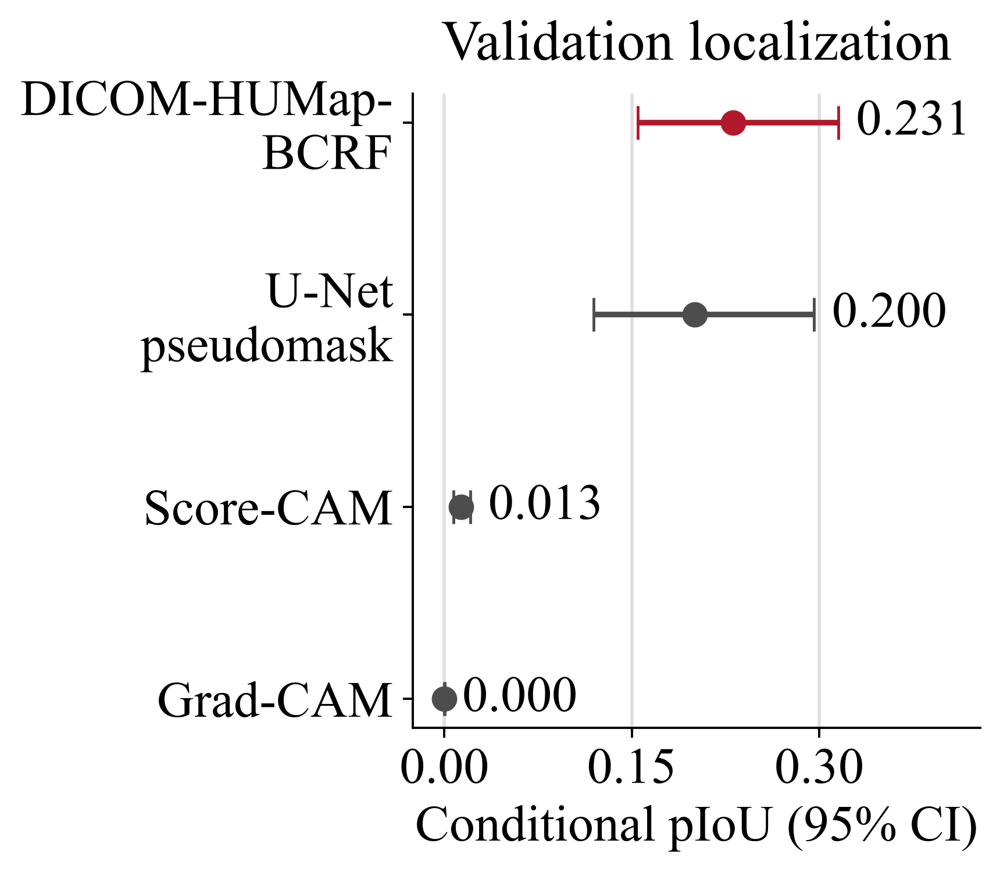

In [36]:
primary_method_order = [
    "DICOM-HUMap-BCRF",
    "U-Net pseudomask",
    "Score-CAM",
    "Grad-CAM",
]

def display_primary_partition(split_name: str, title: str) -> None:
    split_frame = (
        primary_intervals.loc[primary_intervals["split"].eq(split_name)]
        .set_index("method")
        .loc[primary_method_order]
        .reset_index()
    )
    split_frame["display_method"] = split_frame["method"].replace(
        {
            "DICOM-HUMap-BCRF": "DICOM-HUMap-\nBCRF",
            "U-Net pseudomask": "U-Net\npseudomask",
        }
    )
    display_interval_plot(
        split_frame,
        label_column="display_method",
        mean_column="mean",
        low_column="ci95_low",
        high_column="ci95_high",
        title=title,
        xlabel="Conditional pIoU (95% CI)",
        highlight_label="DICOM-HUMap-\nBCRF",
    )

display_primary_partition(
    "validation",
    "Validation localization",
)

### Figure 4.2. Internal retrospective primary localization


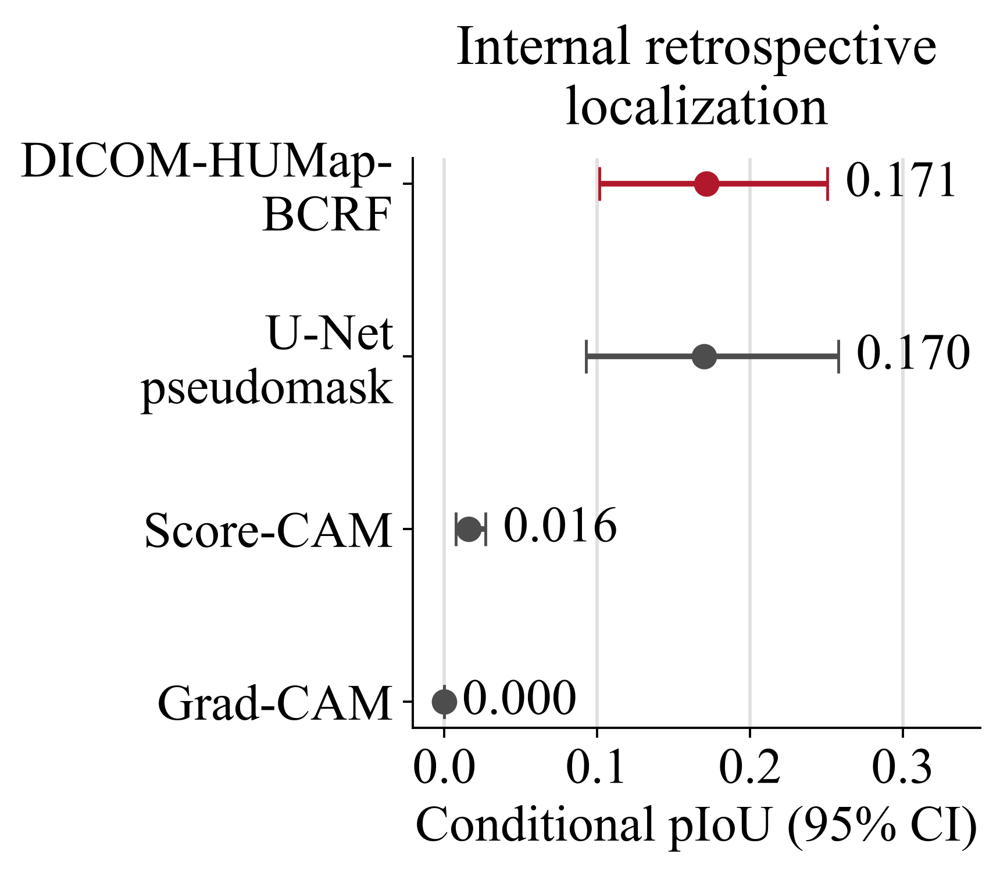

In [37]:
display_primary_partition(
    "locked_test",
    "Internal retrospective\nlocalization",
)

### Figure 4.3. External primary localization


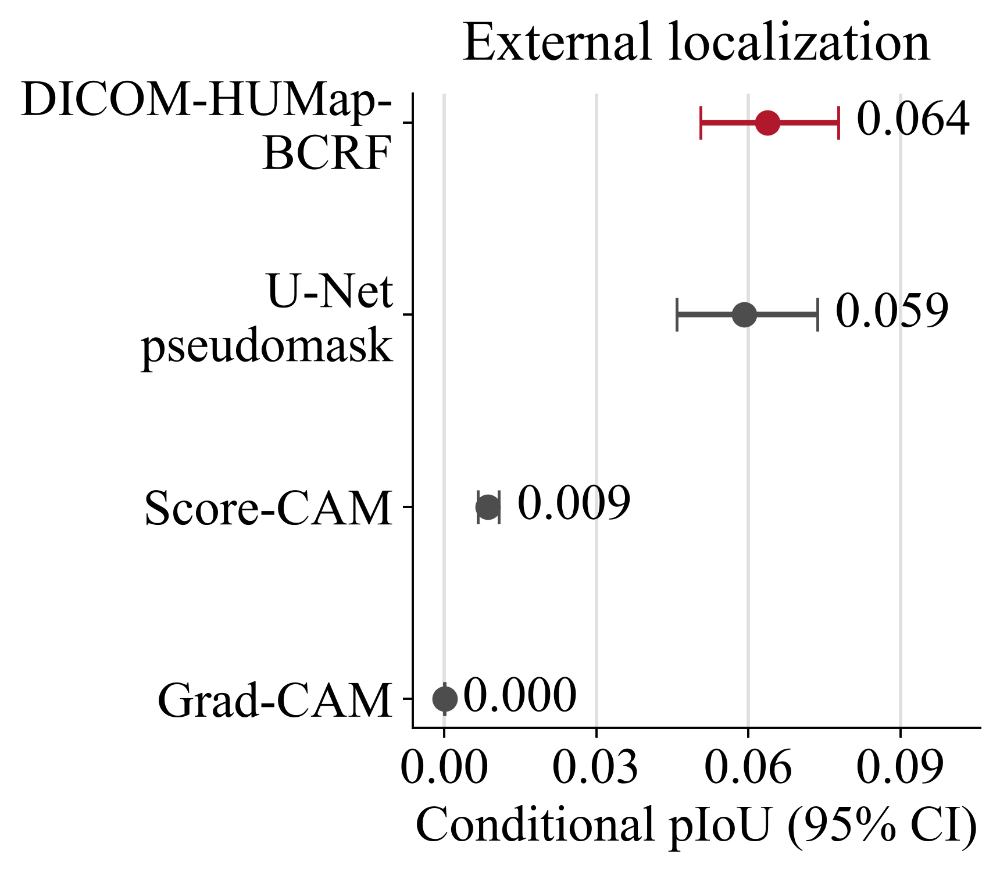

In [38]:
display_primary_partition(
    "cbis_ddsm_calc_test",
    "External localization",
)

### Figure 4.4. Paired primary-localization effects


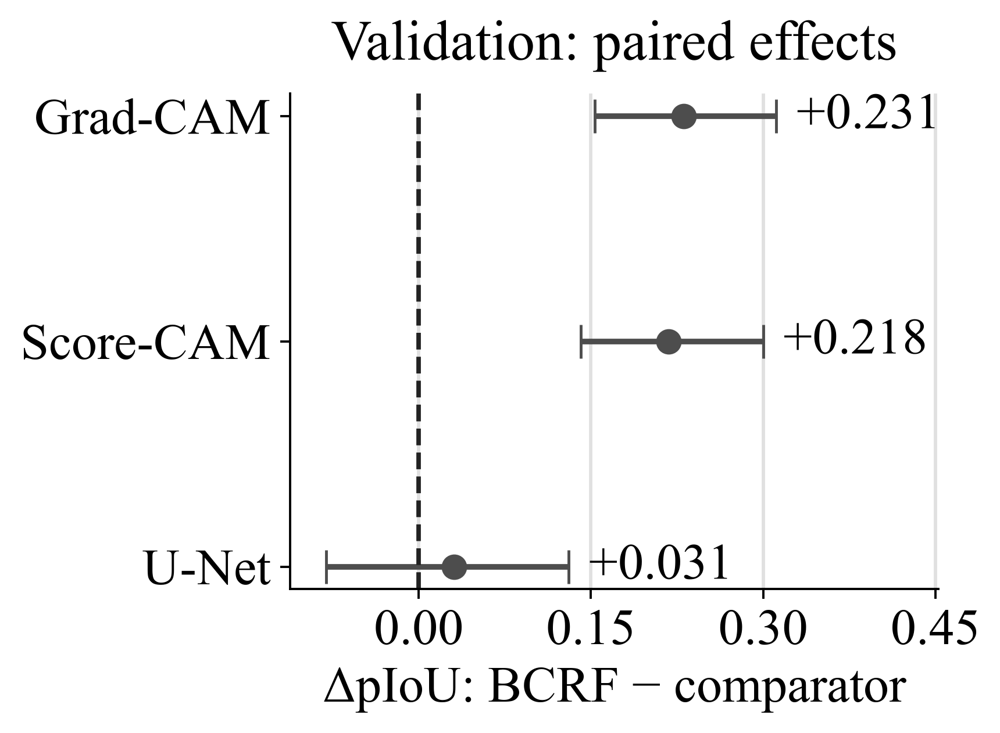

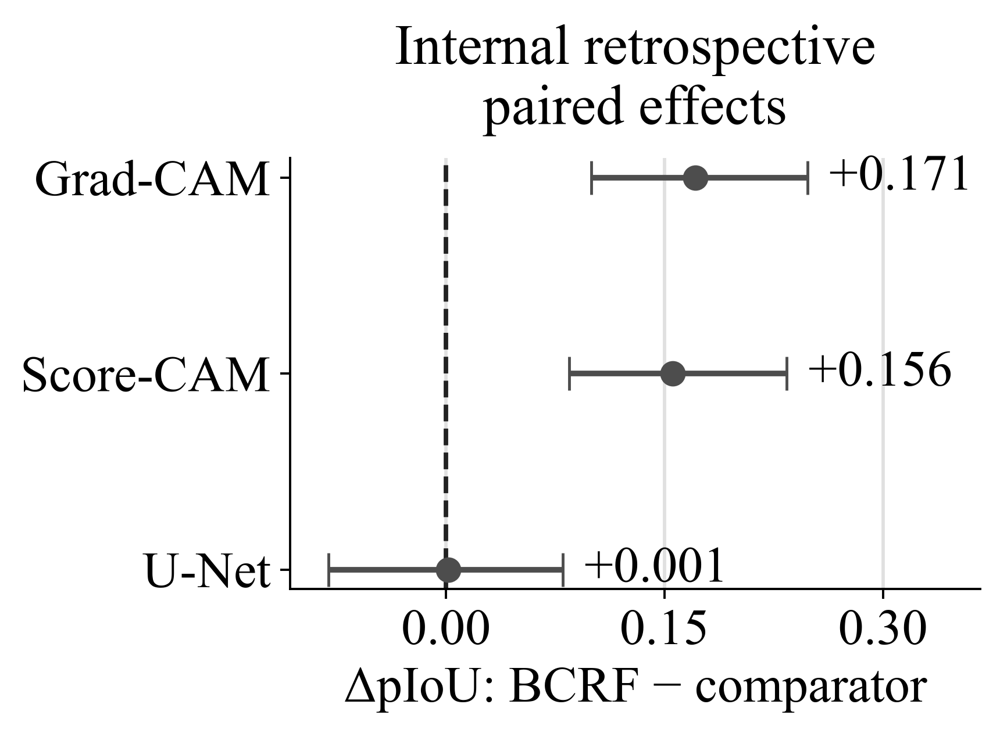

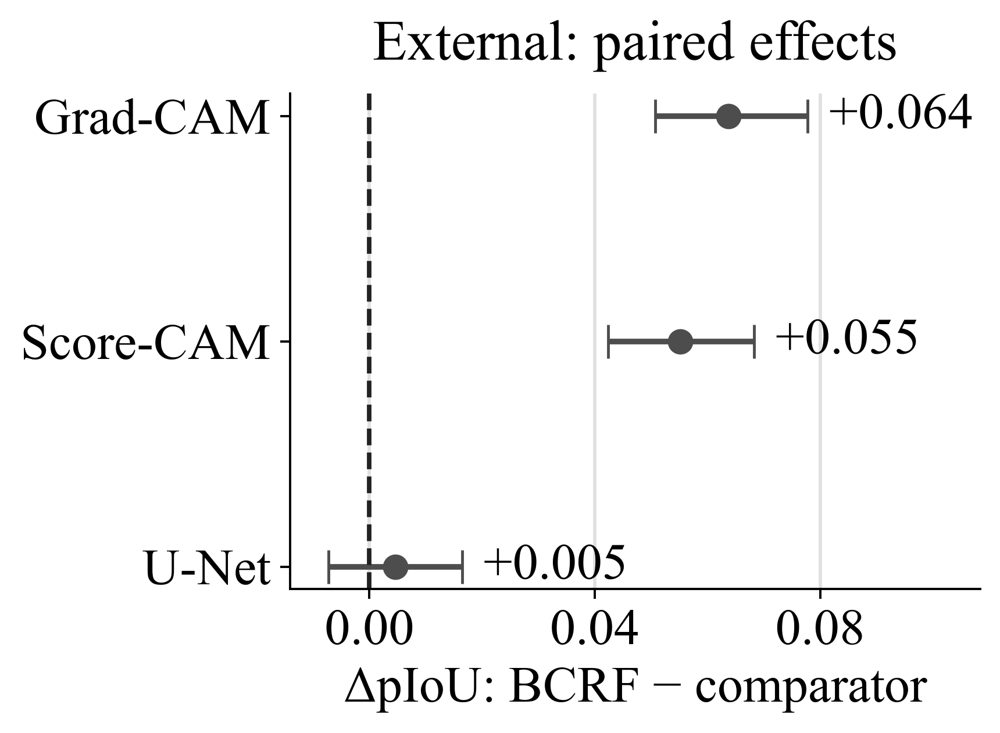

In [39]:
paired_titles = {
    "validation": "Validation: paired effects",
    "locked_test": "Internal retrospective\npaired effects",
    "cbis_ddsm_calc_test": "External: paired effects",
}
for split_name in ["validation", "locked_test", "cbis_ddsm_calc_test"]:
    contrast_frame = (
        paired_contrasts.loc[paired_contrasts["split"].eq(split_name)]
        .sort_values("mean_delta", ascending=False)
        .copy()
    )
    contrast_frame["comparator"] = contrast_frame["comparator"].replace(
        {"U-Net pseudomask": "U-Net"}
    )
    display_interval_plot(
        contrast_frame,
        label_column="comparator",
        mean_column="mean_delta",
        low_column="ci95_low",
        high_column="ci95_high",
        title=paired_titles[split_name],
        xlabel="ΔpIoU: BCRF − comparator",
        reference=0.0,
        signed_values=True,
    )

### Figure 4.5. Paired development-ablation effects


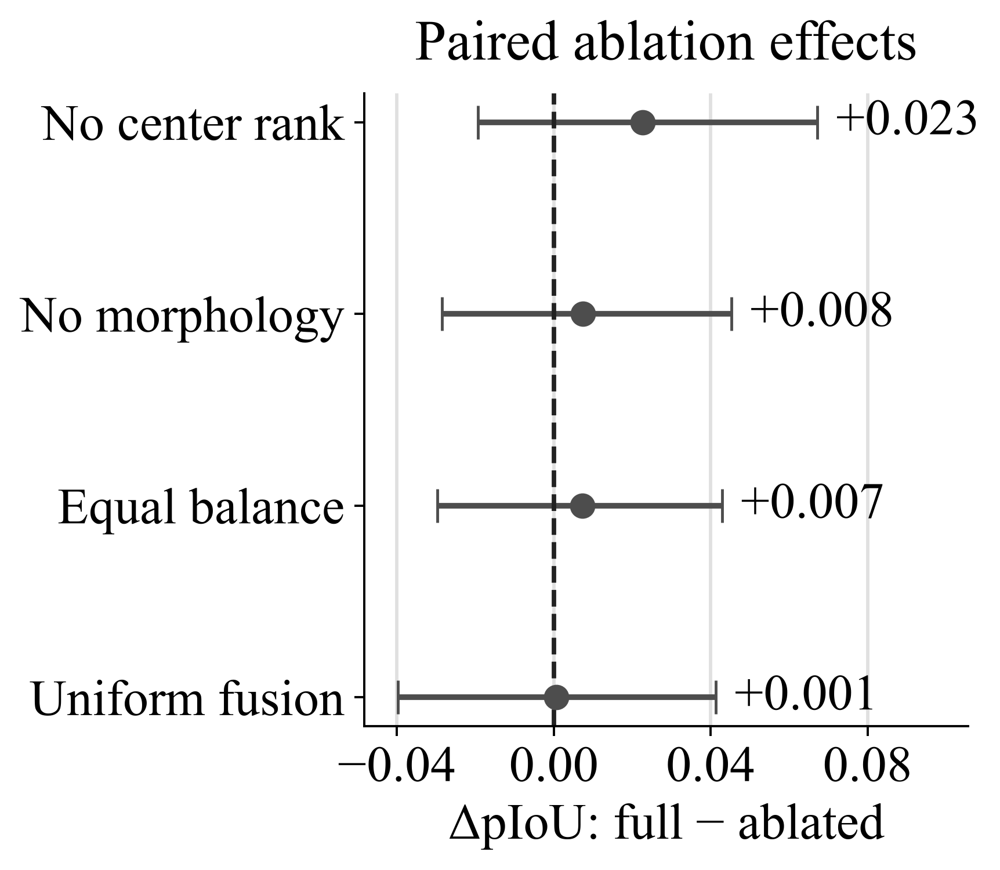

In [40]:
paired_ablation = pd.read_csv(
    MODEL_TABLES / "bcrf_paired_ablation_contrasts.csv"
)
paired_ablation["label"] = (
    paired_ablation["contrast"]
    .str.replace("full_bcrf - ", "", regex=False)
    .str.replace("_", " ", regex=False)
    .str.capitalize()
)
display_interval_plot(
    paired_ablation.sort_values("mean_delta", ascending=False),
    label_column="label",
    mean_column="mean_delta",
    low_column="ci95_low",
    high_column="ci95_high",
    title="Paired ablation effects",
    xlabel="ΔpIoU: full − ablated",
    reference=0.0,
    signed_values=True,
)

### Figure 4.6. DICOM-HUMap-BCRF practical localization


method,probability,penalized_iou,system_penalized_iou
DICOM-HUMap-BCRF,0.425,0.412,0.412
U-Net pseudomask,0.955,0.123,0.123
Score-CAM,0.494,0.008,0.000
Grad-CAM,0.494,0.000,0.000


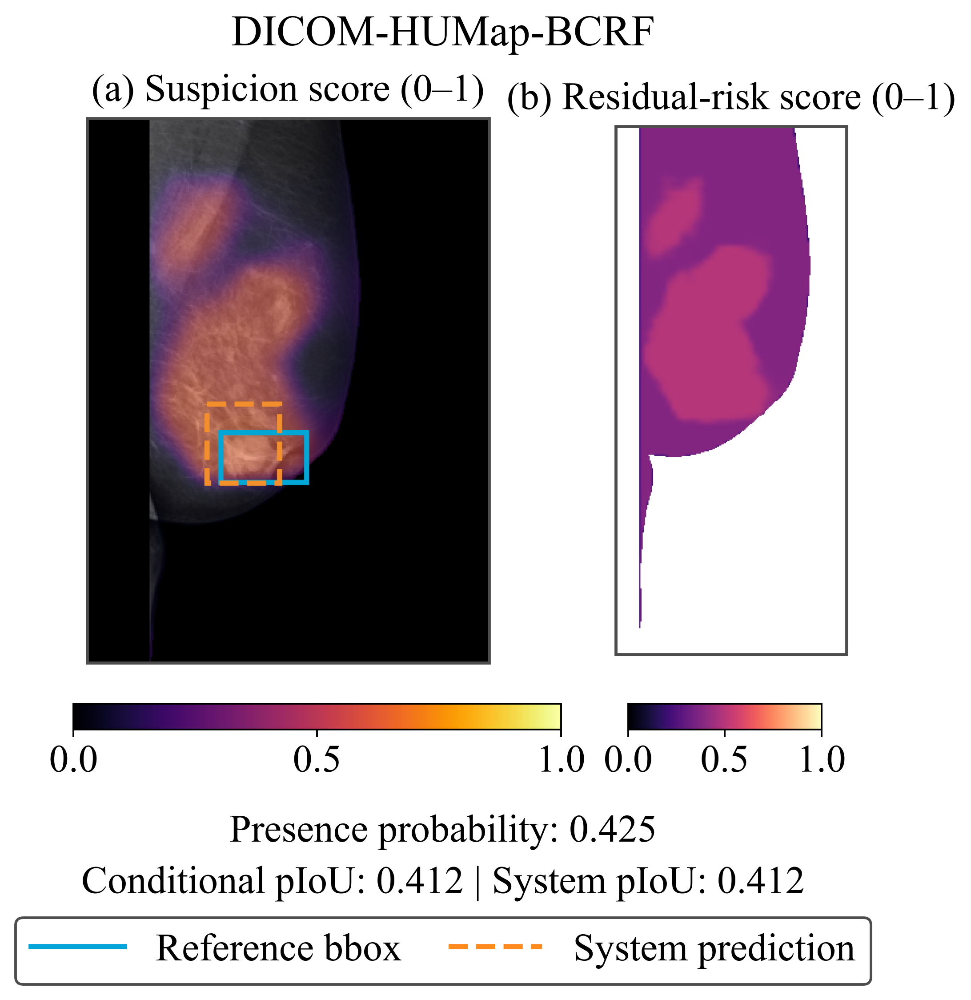

In [41]:
locked_predictions = pd.read_csv(MODEL_TABLES / "locked_test_model_predictions_frozen.csv")
practical_candidates = locked_predictions.loc[
    locked_predictions["method"].eq("DICOM-HUMap-BCRF")
    & locked_predictions["seed"].eq(17)
    & locked_predictions["label"].eq(1),
    ["image_id", "target_boxes_json"],
].copy()
practical_candidates["target_area"] = practical_candidates["target_boxes_json"].map(
    lambda value: sum(max(0.0, x2-x1)*max(0.0, y2-y1) for x1,y1,x2,y2 in json.loads(value))
)
median_area = float(practical_candidates["target_area"].median())
practical_index = (
    practical_candidates["target_area"] - median_area
).abs().idxmin()
practical_image_id = practical_candidates.loc[practical_index, "image_id"]
practical_comparison = locked_predictions.loc[
    locked_predictions["seed"].eq(17)
    & locked_predictions["image_id"].eq(practical_image_id),
    ["method", "probability", "penalized_iou", "system_penalized_iou"],
].copy()
practical_comparison["method"] = practical_comparison["method"].replace(
    {
        "grad_cam": "Grad-CAM",
        "score_cam_top32": "Score-CAM",
        "unet_pseudomask": "U-Net pseudomask",
    }
)
practical_comparison = (
    practical_comparison.set_index("method")
    .loc[primary_method_order]
    .reset_index()
)
show_table(
    practical_comparison,
    caption="Prespecified practical case: frozen seed-17 outputs",
    precision=3,
    highlight_max=["penalized_iou", "system_penalized_iou"],
)
practical_metrics = practical_comparison.set_index("method")
display_practical_model(
    "Figures/Publication_BCRF/06_bcrf_practical_locked_test.png",
    crop_box=(2520, 520, 3650, 2050),
    model_name="DICOM-HUMap-BCRF",
    metrics=practical_metrics.loc["DICOM-HUMap-BCRF"],
    score_label="Suspicion score",
    prediction_visible=True,
    secondary_crop_box=(5150, 520, 5950, 2350),
)

### Figure 4.7. Grad-CAM practical localization


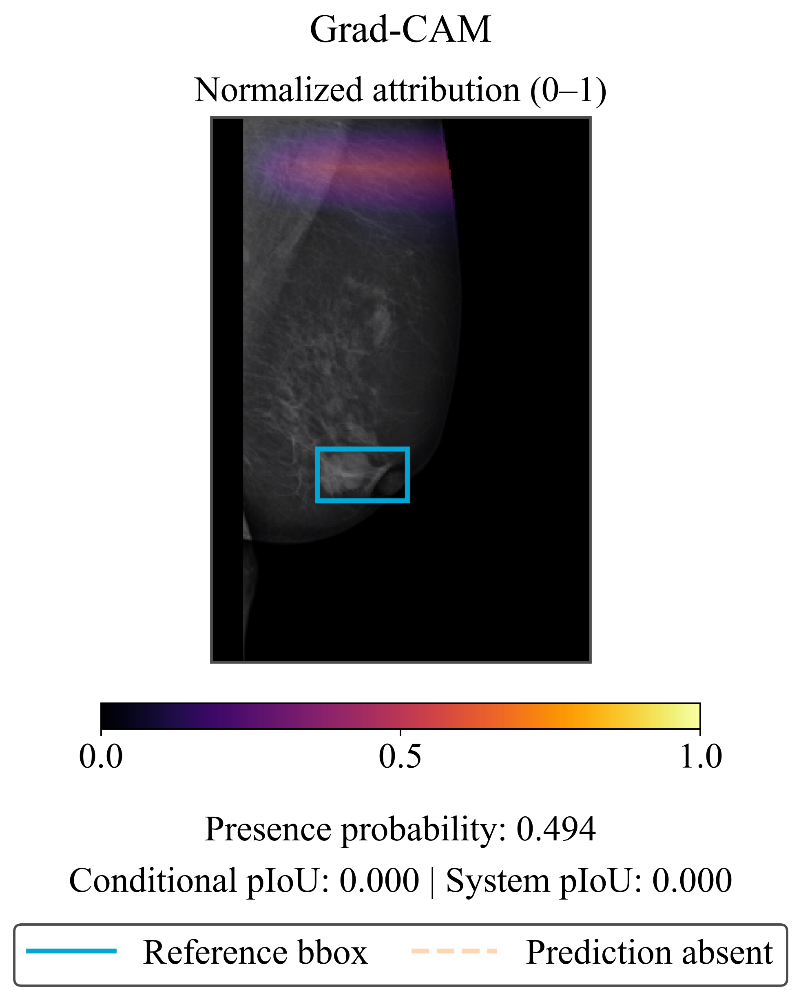

In [42]:
display_practical_model(
    "Figures/Publication_BCRF/07_grad_cam_practical_locked_test.png",
    crop_box=(2900, 520, 4000, 2100),
    model_name="Grad-CAM",
    metrics=practical_metrics.loc["Grad-CAM"],
    score_label="Normalized attribution",
    prediction_visible=False,
)

### Figure 4.8. Score-CAM practical localization


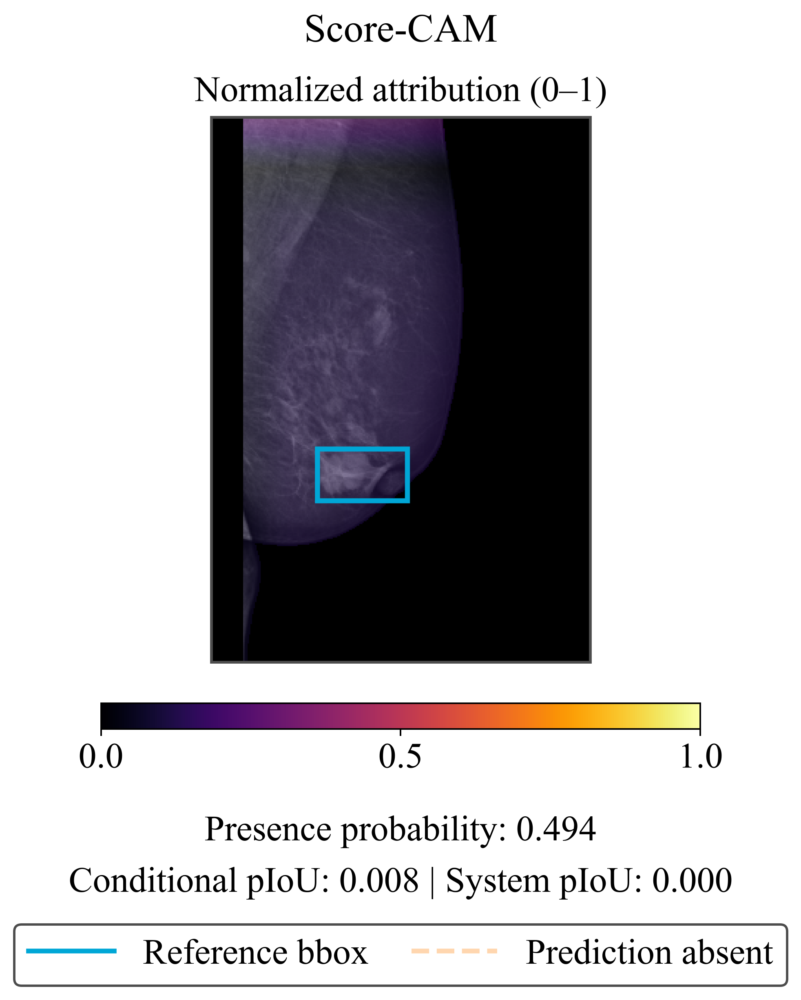

In [43]:
display_practical_model(
    "Figures/Publication_BCRF/08_score_cam_practical_locked_test.png",
    crop_box=(2900, 520, 4000, 2100),
    model_name="Score-CAM",
    metrics=practical_metrics.loc["Score-CAM"],
    score_label="Normalized attribution",
    prediction_visible=False,
)

### Figure 4.9. U-Net practical localization


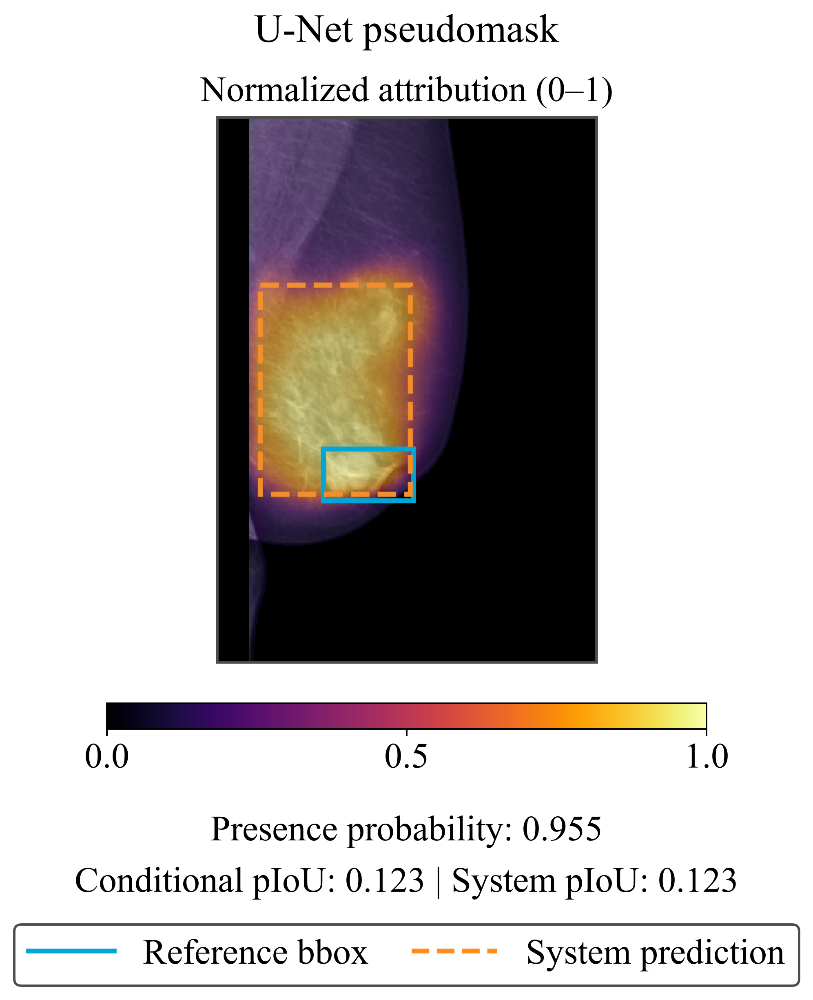

In [44]:
display_practical_model(
    "Figures/Publication_BCRF/09_unet_practical_locked_test.png",
    crop_box=(2900, 520, 4000, 2100),
    model_name="U-Net pseudomask",
    metrics=practical_metrics.loc["U-Net pseudomask"],
    score_label="Normalized attribution",
    prediction_visible=True,
)

### Figure 4.10. BCRF selective risk


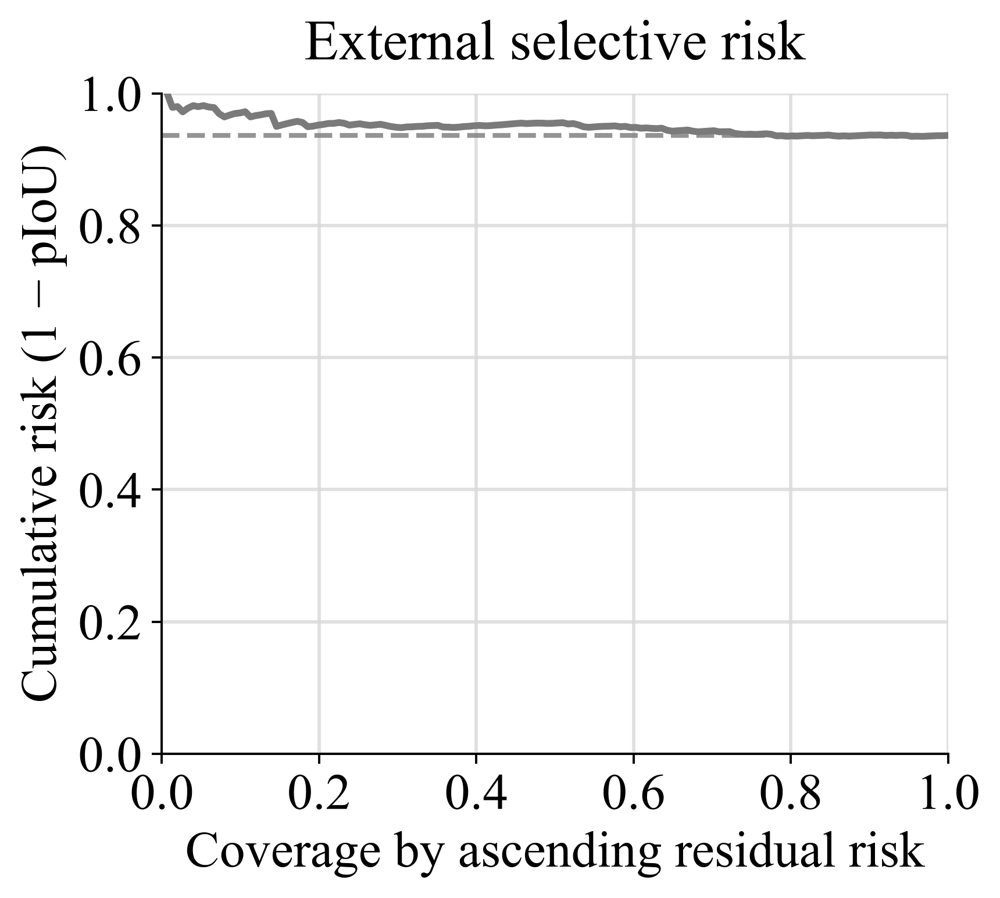

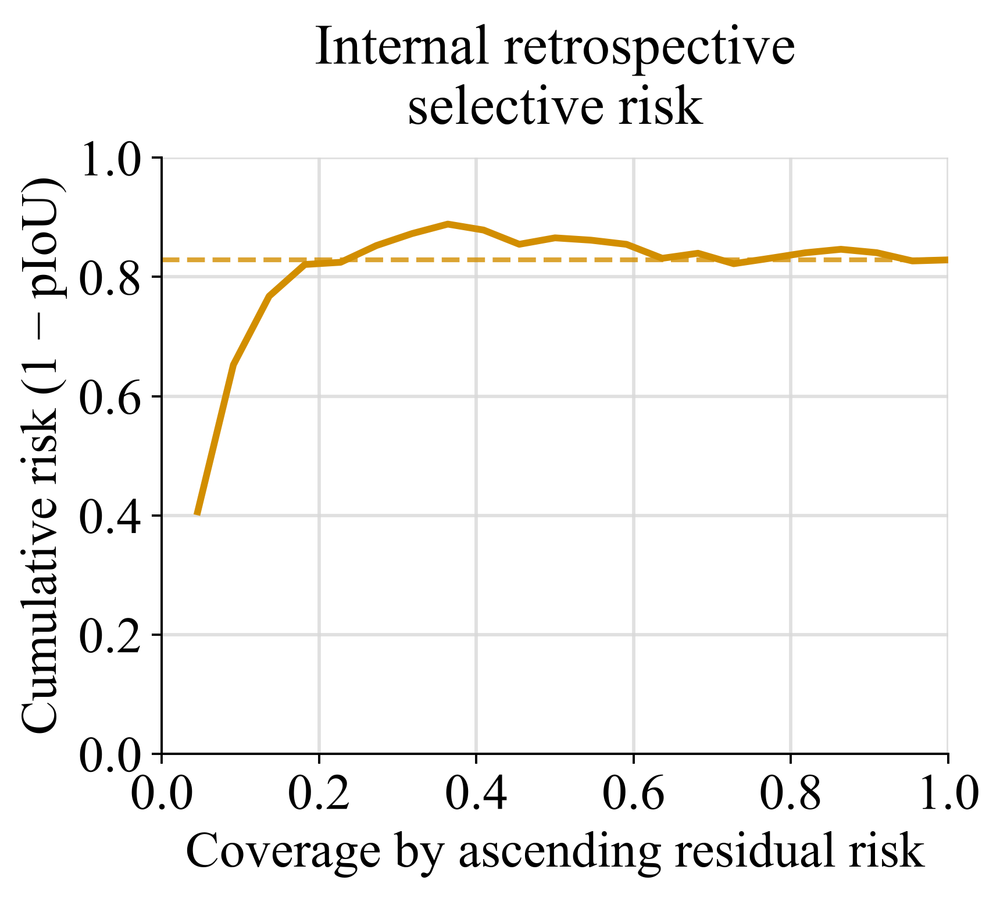

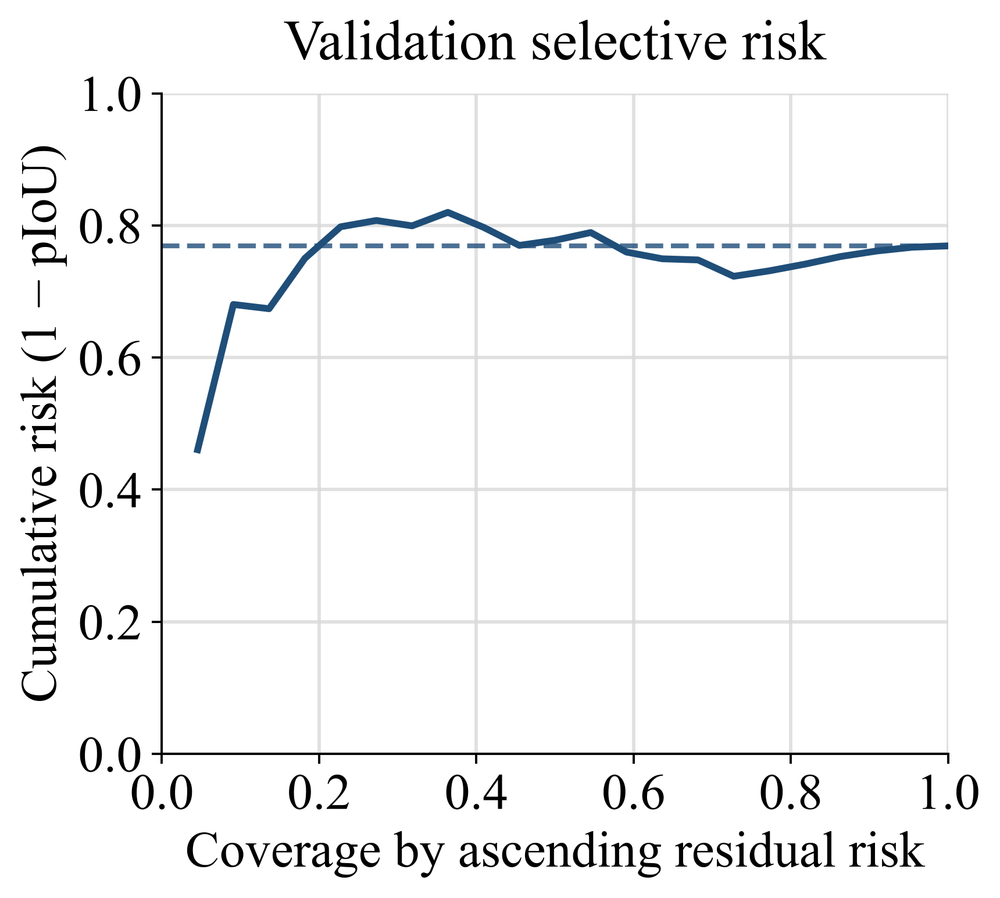

In [45]:
validation_predictions = pd.read_csv(
    MODEL_TABLES / "validation_model_predictions_frozen.csv"
)
external_predictions = pd.read_csv(
    MODEL_TABLES / "cbis_ddsm_calc_test_model_predictions.csv"
)
all_predictions = pd.concat(
    [validation_predictions, locked_predictions, external_predictions],
    ignore_index=True,
)
bcrf_uncertainty = all_predictions.loc[
    all_predictions["method"].eq("DICOM-HUMap-BCRF")
    & all_predictions["label"].eq(1)
    & all_predictions["mean_uncertainty"].notna()
].copy()
uncertainty_study = (
    bcrf_uncertainty.groupby(
        ["split", "seed", "study_id"],
        as_index=False,
    )
    .agg(
        penalized_iou=("penalized_iou", "mean"),
        mean_uncertainty=("mean_uncertainty", "mean"),
    )
    .groupby(["split", "study_id"], as_index=False)
    .mean(numeric_only=True)
)
risk_colors = {
    "validation": "#1F4E79",
    "locked_test": "#D28E00",
    "cbis_ddsm_calc_test": "#7A7A7A",
}
risk_titles = {
    "validation": "Validation selective risk",
    "locked_test": "Internal retrospective\nselective risk",
    "cbis_ddsm_calc_test": "External selective risk",
}
for split_name, split_frame in uncertainty_study.groupby("split", sort=True):
    ordered = split_frame.sort_values("mean_uncertainty")
    risk = 1.0 - ordered["penalized_iou"].to_numpy(dtype=float)
    coverage = np.arange(1, len(risk) + 1) / len(risk)
    selective_risk = np.cumsum(risk) / np.arange(1, len(risk) + 1)
    color = risk_colors[split_name]
    figure, axis = plt.subplots(
        figsize=(4.8, 4.3),
        constrained_layout=True,
    )
    axis.plot(
        coverage,
        selective_risk,
        color=color,
        linewidth=2.4,
    )
    axis.axhline(
        risk.mean(),
        color=color,
        linewidth=1.7,
        linestyle="--",
        alpha=0.80,
    )
    axis.set_xlim(0, 1)
    axis.set_ylim(0, 1)
    axis.set_xlabel("Coverage by ascending residual risk")
    axis.set_ylabel("Cumulative risk (1 − pIoU)")
    axis.set_title(risk_titles[split_name], pad=12)
    clean_axis(axis, grid_axis="both")
    display_scientific_figure(figure)

### Figure 4.11. Secondary classification metrics


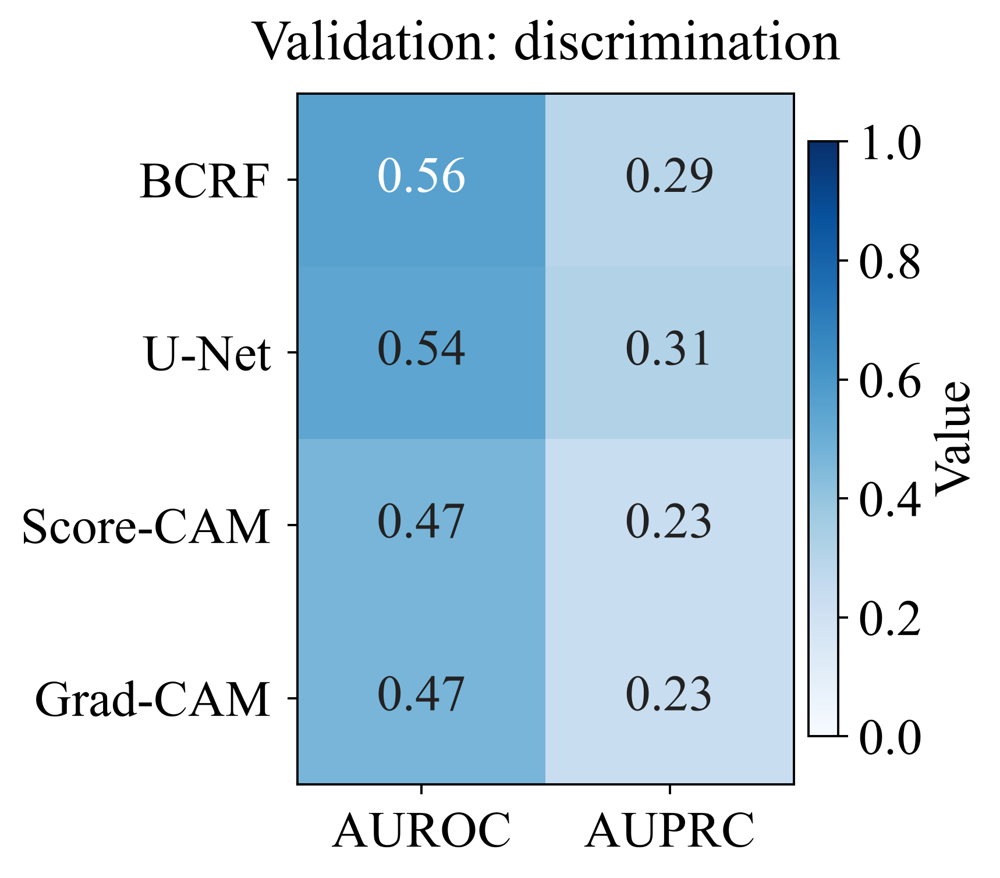

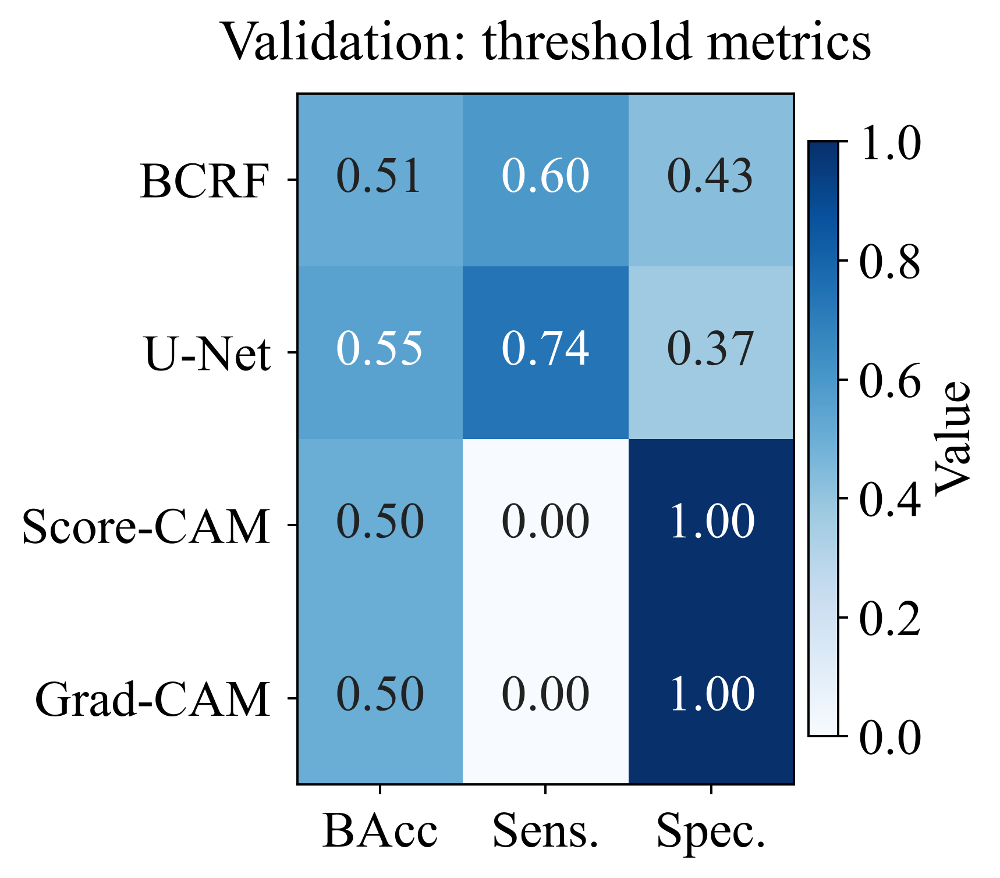

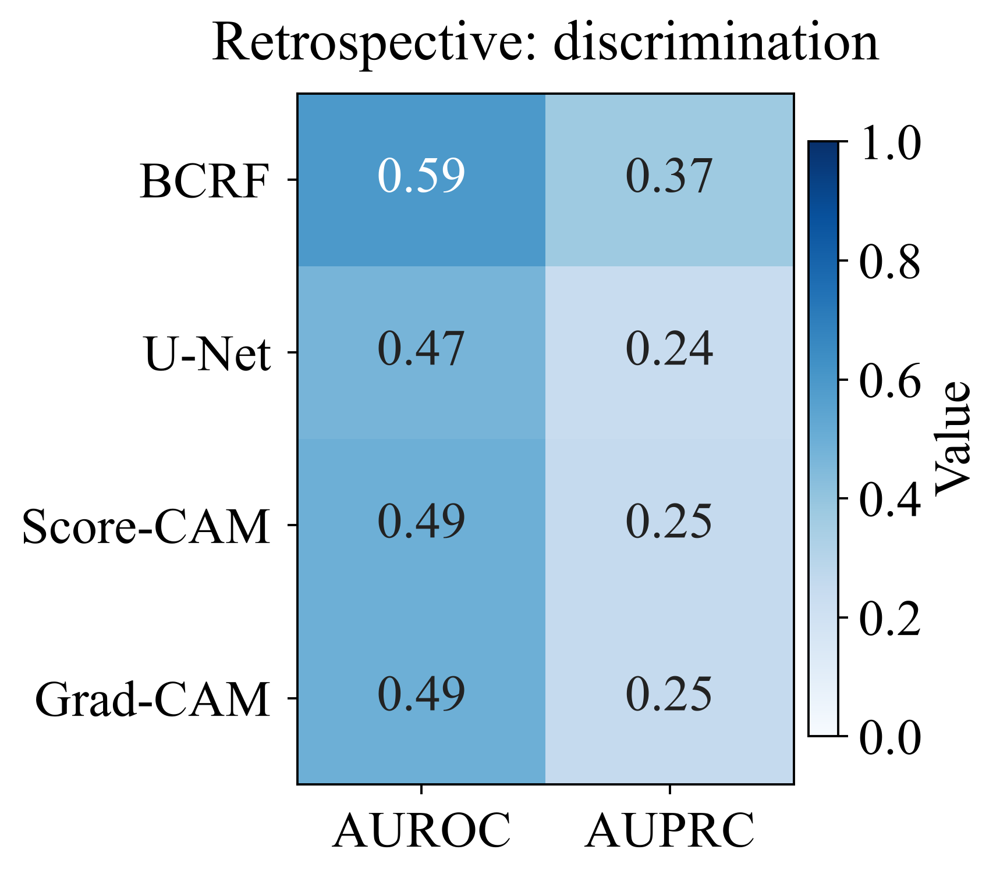

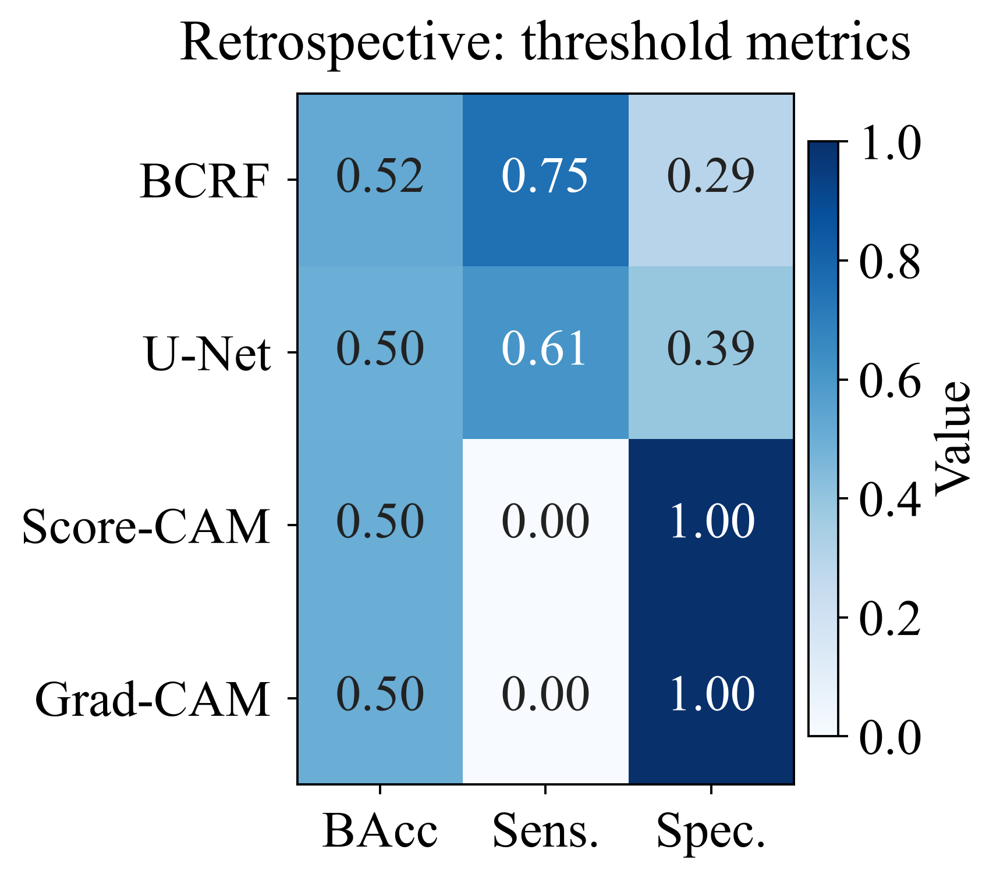

In [46]:
classification_metrics = [
    "auroc_mean",
    "auprc_mean",
    "balanced_accuracy_mean",
    "sensitivity_mean",
    "specificity_mean",
]
classification_labels = [
    "AUROC",
    "AUPRC",
    "Balanced\naccuracy",
    "Sensitivity",
    "Specificity",
]
method_order = [
    "DICOM-HUMap-BCRF",
    "U-Net pseudomask",
    "Score-CAM",
    "Grad-CAM",
]
classification_groups = {
    "Discrimination": (classification_metrics[:2], classification_labels[:2]),
    "Thresholded performance": (classification_metrics[2:], classification_labels[2:]),
}
classification_titles = {
    "validation": "Validation",
    "locked_test": "Retrospective",
}
classification_group_titles = {
    "Discrimination": "discrimination",
    "Thresholded performance": "threshold metrics",
}
for split_name in ["validation", "locked_test"]:
    split_frame = (
        classification_summary.loc[
            classification_summary["split"].eq(split_name)
        ]
        .set_index("method")
        .loc[method_order]
        .reset_index()
    )
    method_labels = split_frame["method"].replace(
        {
            "DICOM-HUMap-BCRF": "BCRF",
            "U-Net pseudomask": "U-Net",
        }
    )
    for group_name, (metric_columns, metric_labels) in classification_groups.items():
        values = split_frame[metric_columns].to_numpy(dtype=float)
        short_metric_labels = [
            {
                "Balanced\naccuracy": "BAcc",
                "Sensitivity": "Sens.",
                "Specificity": "Spec.",
            }.get(label, label)
            for label in metric_labels
        ]
        figure, axis = plt.subplots(
            figsize=(4.8, 4.2),
            constrained_layout=True,
        )
        matrix_image = axis.imshow(
            values,
            cmap="Blues",
            vmin=0,
            vmax=1,
            aspect="auto",
        )
        axis.set_xticks(
            np.arange(len(short_metric_labels)),
            short_metric_labels,
        )
        axis.set_yticks(
            np.arange(len(split_frame)),
            method_labels,
        )
        for row_index in range(values.shape[0]):
            for column_index in range(values.shape[1]):
                value = values[row_index, column_index]
                axis.text(
                    column_index,
                    row_index,
                    format_number(value, decimals=2),
                    ha="center",
                    va="center",
                    color="white" if value >= 0.55 else "#222222",
                    fontsize=18,
                )
        colorbar = figure.colorbar(
            matrix_image,
            ax=axis,
            fraction=0.060,
            pad=0.03,
        )
        colorbar.set_label("Value", fontsize=18)
        colorbar.ax.tick_params(labelsize=18)
        axis.set_title(
            (
                f"{classification_titles[split_name]}: "
                f"{classification_group_titles[group_name]}"
            ),
            pad=12,
        )
        axis.tick_params(labelsize=18, pad=6)
        display_scientific_figure(figure)

## 6. Standard DICOM pre-training pipeline


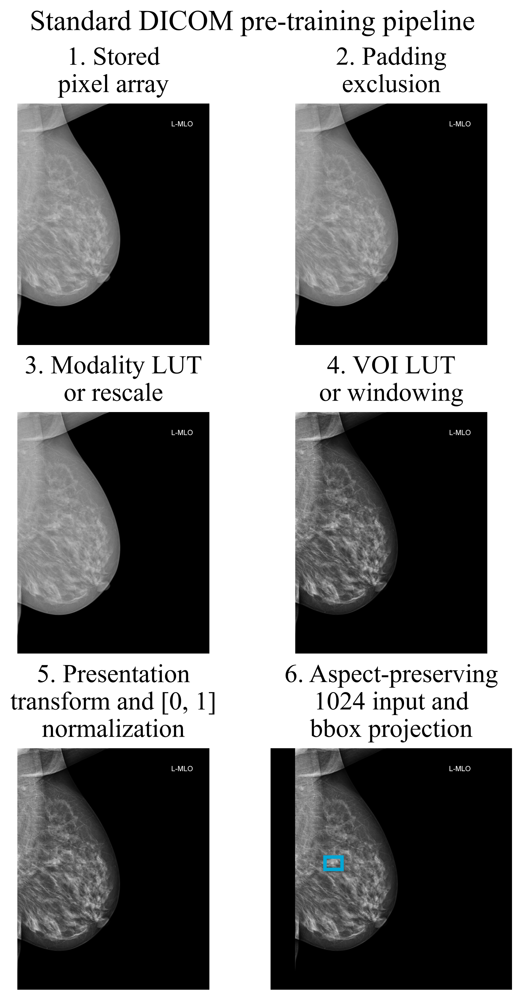

In [ ]:
display(Image(filename=str(resolve_figure("Figures/EDA/F15_standard_dicom_pipeline.png"))))
